# Phân loại âm thanh môi trường ESC-50 bằng CNN và CRNN

**Nghiên cứu ảnh hưởng của biểu diễn Mel-Spectrogram và Data Augmentation**

Notebook này thực hiện toàn bộ đề tài trong proposal: tiền xử lý, huấn luyện CNN và CRNN, 8 thí nghiệm Ablation (E1–E8) với 5-fold cross-validation, kiểm tra độ bền với nhiễu, confusion matrix và ứng dụng demo.

| Mục | Nội dung | Tương ứng proposal |
|---|---|---|
| 1 | Cấu hình chung và 8 cấu hình thí nghiệm | Mục 5 |
| 2 | Tải, đọc và kiểm tra chất lượng dữ liệu ESC-50 | Mục 3 |
| 3 | Tiền xử lý (Log-Mel, chuẩn hóa, SpecAugment) và phân tích khám phá dữ liệu (EDA) | Mục 4 |
| 4 | Mô hình CNN và CRNN | Mục 4 |
| 5–6 | Hàm huấn luyện, đánh giá và tinh chỉnh siêu tham số | Mục 5 |
| 7 | Chạy 8 cấu hình × 5 fold, và fine-tune PANNs CNN14 (E9) làm mô hình tốt nhất | Mục 5 |
| 8 | Kết quả: bảng tổng hợp và từng fold, learning curve, RQ1–RQ3, độ bền, confusion matrix, F1 từng lớp, mẫu dự đoán sai | Mục 6 |
| 9 | Demo: Gradio trong notebook và Streamlit (`app.py`) | Mục 6 |

**Cách chạy (VS Code, trực tiếp trên máy):** mở file bằng VS Code (cần extension Python và Jupyter), chọn kernel Python đã cài PyTorch, rồi chạy các ô từ trên xuống. Notebook **luôn chạy đầy đủ** (E1–E8 × 5 fold × tối đa 80 epoch, rồi E9) và **bắt buộc dùng GPU NVIDIA**: nếu PyTorch chưa nhận GPU, notebook sẽ dừng lại và tự hướng dẫn / tự cài bản PyTorch có CUDA (mục 0), chứ không âm thầm chạy bằng CPU. Chế độ chạy thử nhanh (`QUICK_TEST`: chỉ E1 và E5, 1 fold, 3 epoch) vẫn còn nhưng phải tự bật thủ công ở mục 1. Mọi file kết quả (`results/`, `checkpoints/`, `demo/`) được tạo ngay cạnh file notebook.

**Câu hỏi nghiên cứu:**
- **RQ1:** CRNN có nhận dạng tốt hơn CNN không?
- **RQ2:** 128 Mel bins có tốt hơn 64 Mel bins không?
- **RQ3:** SpecAugment có giúp mô hình tốt hơn và bền hơn khi âm thanh bị nhiễu không?

## 0. Cài đặt thư viện và kiểm tra GPU

1. Chạy ô cài thư viện thông thường.
2. Chạy ô **"Kiểm tra và cài PyTorch bản GPU"**: ô này chạy trước khi `import torch`, tự phát hiện GPU NVIDIA bằng `nvidia-smi`, kiểm tra PyTorch hiện tại là bản CPU hay bản CUDA, và (nếu `AUTO_INSTALL_CUDA_TORCH = True`) tự cài đúng bản CUDA phù hợp với driver.
3. Chạy ô kiểm tra máy. Nếu vẫn không có GPU, ô này báo lỗi rõ ràng thay vì chạy bằng CPU.
4. Chuẩn bị sẵn thư mục dữ liệu **ESC-50** (thư mục chứa `meta/esc50.csv` và `audio/`), ghi đường dẫn vào biến `ESC_PATH` ở mục 2.

> **Lưu ý (Windows):** lệnh `pip install torch` mặc định trên Windows cài bản **CPU-only**. Đây là nguyên nhân phổ biến nhất khiến `torch.cuda.is_available()` trả về `False` dù máy có GPU NVIDIA.

In [1]:
%pip install -q soundfile gradio ipywidgets scikit-learn pandas matplotlib scipy tqdm psutil


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
# ===== Kiểm tra và cài PyTorch bản GPU (CUDA) =====
# Ô này KHÔNG import torch trong kernel, nên có thể gỡ/cài lại PyTorch an toàn (kể cả trên Windows,
# nơi file DLL đang được dùng sẽ không ghi đè được).
import json, re, shutil, subprocess, sys
from pathlib import Path

AUTO_INSTALL_CUDA_TORCH = True   # True: nếu PyTorch là bản CPU (hoặc hỏng) thì tự cài bản CUDA. False: chỉ chẩn đoán và in lệnh


def _run(cmd):
    return subprocess.run(cmd, capture_output=True, text=True)


def _stream(cmd):
    print("$", " ".join(cmd))
    p = subprocess.Popen(cmd, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, bufsize=1)
    for line in p.stdout:
        print(line.rstrip())
    return p.wait()


def probe_torch():
    # Kiểm tra PyTorch trong một tiến trình riêng (không làm kernel này import torch)
    code = (
        "import json, torch\n"
        "d = dict(version=torch.__version__, cuda_build=torch.version.cuda,\n"
        "         available=torch.cuda.is_available(), gpu=None, audio=None)\n"
        "if d['available']:\n"
        "    d['gpu'] = torch.cuda.get_device_name(0)\n"
        "try:\n"
        "    import torchaudio\n"
        "    d['audio'] = torchaudio.__version__\n"
        "except Exception:\n"
        "    d['audio'] = None\n"
        "print('JSON:' + json.dumps(d))\n"
    )
    r = _run([sys.executable, "-c", code])
    for line in r.stdout.splitlines():
        if line.startswith("JSON:"):
            return json.loads(line[5:])
    return None   # chưa cài torch, hoặc import bị lỗi


def _driver_to_cuda(drv):
    # Suy ra CUDA tối đa mà driver Windows hỗ trợ từ số hiệu driver (dùng khi nvidia-smi không in dòng "CUDA Version")
    for need, cuda in ((580.0, (13, 0)), (570.0, (12, 8)), (560.0, (12, 6)),
                       (550.0, (12, 4)), (520.0, (11, 8))):
        if drv >= need:
            return cuda
    return None


def nvidia_smi():
    exe = shutil.which("nvidia-smi")
    if exe is None:
        for p in (r"C:\Windows\System32\nvidia-smi.exe",
                  r"C:\Program Files\NVIDIA Corporation\NVSMI\nvidia-smi.exe"):
            if Path(p).exists():
                exe = p
                break
    if exe is None:
        return None
    head = _run([exe]).stdout
    q = _run([exe, "--query-gpu=name,driver_version", "--format=csv,noheader"]).stdout.strip()
    cuda = None
    m = re.search(r"CUDA Version:\s*(\d+)\.(\d+)", head)
    if m:
        cuda = (int(m.group(1)), int(m.group(2)))
    else:   # không đọc được dòng CUDA Version: dựa vào số hiệu driver
        m = re.search(r"(\d+)\.(\d+)\s*$", q.splitlines()[0] if q else "")
        if m:
            cuda = _driver_to_cuda(float(f"{m.group(1)}.{m.group(2)}"))
    return dict(cuda=cuda, info=q)


def pick_wheel(cuda):
    # (CUDA tối thiểu mà driver hỗ trợ, tên kênh wheel, phiên bản torch/torchaudio)
    options = [((13, 0), "cu130", "2.9.1"), ((12, 8), "cu128", "2.9.1"),
               ((12, 6), "cu126", "2.9.1"), ((11, 8), "cu118", "2.7.1")]
    for need, tag, ver in options:
        if cuda >= need:
            return tag, ver
    return None


info = probe_torch()
smi = nvidia_smi()

print("Python:", sys.version.split()[0], "|", sys.executable)
if info:
    print(f"PyTorch hiện tại: {info['version']} | CUDA build: {info['cuda_build']} | "
          f"nhận GPU: {info['available']} | torchaudio: {info['audio']}")
else:
    print("PyTorch hiện tại: chưa cài hoặc import bị lỗi")
print("NVIDIA:", (smi["info"] + f" | driver hỗ trợ tới CUDA {smi['cuda']}") if smi else "không tìm thấy nvidia-smi")

if info and info["available"] and info["audio"]:
    print(f"\nOK: PyTorch đã nhận GPU ({info['gpu']}). Chạy tiếp các ô bên dưới.")
elif smi is None:
    print("\nKHÔNG tìm thấy nvidia-smi: máy chưa cài driver NVIDIA, hoặc không có GPU NVIDIA.\n"
          "- Cài driver mới nhất tại https://www.nvidia.com/Download/index.aspx rồi khởi động lại máy.\n"
          "- Nếu máy dùng GPU AMD/Intel hoặc không có GPU rời thì notebook này không chạy được bằng GPU "
          "(có thể dùng Google Colab / Kaggle có GPU).")
elif smi["cuda"] is None or pick_wheel(smi["cuda"]) is None:
    print(f"\nKhông xác định được CUDA mà driver hỗ trợ, hoặc driver quá cũ (CUDA {smi['cuda']}). Hãy cập nhật driver tại "
          "https://www.nvidia.com/Download/index.aspx, khởi động lại máy rồi chạy lại ô này.")
else:
    tag, ver = pick_wheel(smi["cuda"])
    url = f"https://download.pytorch.org/whl/{tag}"
    if info is None:
        why = "chưa cài PyTorch hoặc PyTorch bị lỗi."
    elif info["cuda_build"] is None:
        why = "PyTorch đang cài là bản CPU-only (đây là lý do GPU không được nhận)."
    elif not info["available"]:
        why = f"PyTorch là bản CUDA {info['cuda_build']} nhưng không nhận GPU (có thể lệch với driver)."
    else:
        why = "thiếu hoặc lỗi torchaudio (không khớp với torch)."
    print(f"\nVấn đề: {why}")
    uninstall = [sys.executable, "-m", "pip", "uninstall", "-y", "torch", "torchaudio"]
    install = [sys.executable, "-m", "pip", "install", "--progress-bar", "off",
               f"torch=={ver}", f"torchaudio=={ver}", "--index-url", url]
    print("Cách sửa (dung lượng tải khoảng 2,5-3 GB):")
    print("  python " + " ".join(uninstall[1:]))
    print("  python " + " ".join(install[1:]))

    if "torch" in sys.modules:
        print("\nKernel này đã import torch trước đó nên không gỡ được (nhất là trên Windows). "
              "Hãy bấm Restart trên thanh công cụ của notebook rồi chạy lại từ ô này.")
    elif not AUTO_INSTALL_CUDA_TORCH:
        print("\nAUTO_INSTALL_CUDA_TORCH = False: hãy tự chạy hai lệnh trên trong Terminal (cùng môi trường Python), "
              "rồi Restart kernel.")
    else:
        print("\nĐang cài, vui lòng đợi...")
        _stream(uninstall)
        code_rc = _stream(install)
        info = probe_torch()
        if code_rc == 0 and info and info["available"]:
            print(f"\nXONG: PyTorch {info['version']} đã nhận GPU ({info['gpu']}). Chạy tiếp các ô bên dưới.")
        else:
            print("\nĐã cài nhưng PyTorch vẫn chưa nhận GPU. Thử lần lượt: (1) khởi động lại máy, "
                  "(2) cập nhật driver NVIDIA, (3) chạy lại ô này.")


Python: 3.13.3 | c:\Users\tnmt1\AppData\Local\Programs\Python\Python313\python.exe
PyTorch hiện tại: 2.9.1+cu130 | CUDA build: 13.0 | nhận GPU: True | torchaudio: 2.9.1+cu130
NVIDIA: NVIDIA GeForce RTX 3080 Laptop GPU, 610.62 | driver hỗ trợ tới CUDA (13, 0)

OK: PyTorch đã nhận GPU (NVIDIA GeForce RTX 3080 Laptop GPU). Chạy tiếp các ô bên dưới.


In [3]:
import os, platform, shutil, sys
import torch

ALLOW_CPU = False   # True: cho phép chạy bằng CPU (rất chậm). Mặc định False để KHÔNG âm thầm rơi về CPU

print("Python:", sys.version.split()[0], "|", platform.system())
print("PyTorch:", torch.__version__, "| CUDA build:", torch.version.cuda)

if torch.cuda.is_available():
    props = torch.cuda.get_device_properties(0)
    print(f"GPU: {props.name} | VRAM {props.total_memory / 1e9:.1f} GB | compute capability {props.major}.{props.minor}")
    arch = f"sm_{props.major}{props.minor}"
    if arch not in torch.cuda.get_arch_list():
        print(f"CẢNH BÁO: bản PyTorch này chưa hỗ trợ kiến trúc {arch} của GPU. "
              "Hãy chạy lại ô cài đặt ở trên để cài bản CUDA mới hơn.")
    try:   # chạy thử một phép tính thật trên GPU
        a = torch.randn(256, 256, device="cuda")
        (a @ a).sum().item()
        torch.cuda.synchronize()
        print("Phép tính thử trên GPU: OK")
    except Exception as e:
        raise RuntimeError(f"GPU được nhận nhưng không chạy được phép tính: {e}\n"
                           "Thường do driver cũ hoặc bản PyTorch không khớp. Chạy lại ô cài đặt ở trên.") from e
else:
    reason = ("PyTorch đang cài là bản CPU-only (CUDA build = None). Chạy ô \"Kiểm tra và cài PyTorch bản GPU\" "
              "ở trên với AUTO_INSTALL_CUDA_TORCH = True, rồi bấm Restart kernel và chạy lại."
              if torch.version.cuda is None else
              "PyTorch là bản CUDA nhưng không nhận GPU. Hãy cập nhật driver NVIDIA, khởi động lại máy, "
              "rồi chạy lại ô cài đặt ở trên.")
    msg = "Không dùng được GPU. " + reason
    if not ALLOW_CPU:
        raise RuntimeError(msg)
    print("CẢNH BÁO:", msg, "\nĐang chạy bằng CPU vì ALLOW_CPU = True (rất chậm).")

try:
    import psutil
    print(f"RAM trống: {psutil.virtual_memory().available / 1e9:.1f} GB (cần khoảng 4 GB)")
except ImportError:
    pass
print(f"Ổ đĩa trống: {shutil.disk_usage('.').free / 1e9:.1f} GB (cần khoảng 3 GB nếu chạy E9)")
print("Thư mục làm việc (nơi lưu ESC-50, results, checkpoints, demo):", os.getcwd())


Python: 3.13.3 | Windows
PyTorch: 2.9.1+cu130 | CUDA build: 13.0
GPU: NVIDIA GeForce RTX 3080 Laptop GPU | VRAM 8.6 GB | compute capability 8.6
Phép tính thử trên GPU: OK
RAM trống: 16.0 GB (cần khoảng 4 GB)
Ổ đĩa trống: 377.5 GB (cần khoảng 3 GB nếu chạy E9)
Thư mục làm việc (nơi lưu ESC-50, results, checkpoints, demo): d:\codeee\Project py\DL


## 1. Cấu hình chung

In [4]:
import copy, os, random, subprocess, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import soundfile as sf
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchaudio.transforms as T
import matplotlib.pyplot as plt
from IPython.display import display
from scipy import stats
from sklearn.metrics import (accuracy_score, confusion_matrix, f1_score,
                             precision_recall_fscore_support)
from torch.utils.data import DataLoader, Subset, TensorDataset
from tqdm.auto import tqdm

warnings.filterwarnings("ignore")
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.backends.cudnn.benchmark = True
USE_AMP = DEVICE.type == "cuda"      # mixed precision (FP16) trên GPU: nhanh hơn và tiết kiệm VRAM
print("Thiết bị:", DEVICE, "|", torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "CPU", "| AMP:", USE_AMP)

# ---- Công tắc chạy ----
# Mặc định chạy ĐẦY ĐỦ: E1-E8 x 5 fold x tối đa 80 epoch (rồi E9), không phụ thuộc có GPU hay không.
# Chỉ đặt True khi muốn chạy thử nhanh (chỉ E1, E5, 1 fold, 3 epoch).
QUICK_TEST = False
print("Chế độ:", "chạy thử nhanh (CHỈ E1, E5, 1 fold, 3 epoch)" if QUICK_TEST else "chạy đầy đủ (E1-E8 x 5 fold)")
RUN_TUNING = False   # True: chạy bước tinh chỉnh siêu tham số (mục 6)

# ---- Thiết lập chung (theo proposal) ----
CFG = dict(
    SAMPLE_RATE=22050,      # resample từ 44,1 kHz xuống 22,05 kHz
    DURATION=5,             # giây
    N_FFT=1024,
    HOP_LENGTH=512,
    BATCH_SIZE=32,
    LR=1e-3,
    WEIGHT_DECAY=1e-2,
    EPOCHS=80,
    PATIENCE=80,            # = EPOCHS: KHÔNG dừng sớm, luôn chạy đủ 80 epoch (mô hình lưu vẫn là epoch có Macro-F1 validation tốt nhất). Đặt 15 để bật lại dừng sớm
    FREQ_MASK_RATIO=0.125,  # độ rộng tối đa mặt nạ tần số = 12,5% số Mel bins
    TIME_MASK_PARAM=20,     # độ rộng tối đa mặt nạ thời gian (khung)
    NUM_MASKS=2,            # số mặt nạ mỗi loại
    CONV_PER_BLOCK=2,       # số lớp Conv2D trong mỗi khối (mô hình sâu hơn)
    LABEL_SMOOTHING=0.1,    # làm mềm nhãn, giảm học vẹt
    BASE_AUG=True,          # augmentation cơ bản (dịch thời gian + đổi âm lượng), dùng chung cho mọi cấu hình
    SHIFT_MAX=0.5,          # dịch vòng tối đa theo tỷ lệ độ dài clip
    GAIN_DB=6.0,            # đổi âm lượng ngẫu nhiên trong khoảng +-GAIN_DB
    SNR_LIST=[20, 10, 0],   # mức nhiễu Gaussian khi kiểm tra độ bền (dB)
    NUM_CLASSES=50,
    SEED=42,
)

# ---- 8 cấu hình Ablation ----
EXPERIMENTS = {
    "E1": dict(model="cnn",  n_mels=64,  specaug=False),
    "E2": dict(model="cnn",  n_mels=128, specaug=False),
    "E3": dict(model="cnn",  n_mels=64,  specaug=True),
    "E4": dict(model="cnn",  n_mels=128, specaug=True),
    "E5": dict(model="crnn", n_mels=64,  specaug=False),
    "E6": dict(model="crnn", n_mels=128, specaug=False),
    "E7": dict(model="crnn", n_mels=64,  specaug=True),
    "E8": dict(model="crnn", n_mels=128, specaug=True),
}
EXP_IDS = list(EXPERIMENTS)
FOLDS = [1, 2, 3, 4, 5]

if QUICK_TEST:
    CFG["EPOCHS"] = 3
    EXP_IDS = ["E1", "E5"]
    FOLDS = [1]

SAVE_ROOT = Path(".")   # lưu ngay cạnh notebook
RESULT_DIR = SAVE_ROOT / ("results_quick" if QUICK_TEST else "results")
CKPT_DIR = SAVE_ROOT / ("checkpoints_quick" if QUICK_TEST else "checkpoints")
RESULT_DIR.mkdir(exist_ok=True)
CKPT_DIR.mkdir(exist_ok=True)


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


set_seed(CFG["SEED"])
SR = CFG["SAMPLE_RATE"]
TARGET_LEN = SR * CFG["DURATION"]

Thiết bị: cuda | NVIDIA GeForce RTX 3080 Laptop GPU | AMP: True
Chế độ: chạy đầy đủ (E1-E8 x 5 fold)


## 2. Dữ liệu ESC-50

ESC-50 gồm 2.000 file WAV (5 giây, 44,1 kHz, mono), 50 lớp, mỗi lớp 40 file, chia sẵn thành 5 fold. Nhãn và số fold đọc từ `meta/esc50.csv`.

In [5]:
# Thư mục ESC-50 có sẵn trên máy (thư mục chứa meta/esc50.csv và audio/).
# Dùng dấu gạch chéo / trong đường dẫn (chạy được cả trên Windows, kể cả khi có dấu cách).
# Đặt None nếu muốn notebook tự tìm trong các vị trí thường gặp cạnh notebook.
ESC_PATH = "D:/codeee/Project py/DL/ESC-50-master"


def find_esc50(custom=None):
    candidates = []
    if custom:
        base = Path(custom)
        candidates += [base, base / "ESC-50-master", base / "ESC-50"]
    candidates += [Path("ESC-50"), Path("ESC-50-master"), Path("../ESC-50"),
                   Path("../ESC-50-master"), Path("data/ESC-50"), Path("data/ESC-50-master")]
    for p in candidates:
        if (p / "meta" / "esc50.csv").exists() and (p / "audio").is_dir():
            return p
    return None


ESC_DIR = find_esc50(ESC_PATH)
if ESC_DIR is None:
    raise FileNotFoundError(
        "Không tìm thấy thư mục ESC-50 (cần có meta/esc50.csv và audio/). "
        "Hãy đặt thư mục ESC-50 cạnh notebook, hoặc ghi đường dẫn vào biến ESC_PATH.")
print("Dùng dữ liệu ESC-50 tại:", ESC_DIR.resolve())

meta = pd.read_csv(ESC_DIR / "meta" / "esc50.csv")
CLASS_NAMES = meta.drop_duplicates("target").sort_values("target")["category"].tolist()
assert len(CLASS_NAMES) == CFG["NUM_CLASSES"]

# 5 nhóm lớn: lớp có chỉ số 0-9, 10-19, ... thuộc cùng một nhóm
GROUP_NAMES = ["Động vật", "Thiên nhiên và nước", "Âm thanh con người",
               "Âm thanh trong nhà", "Tiếng ồn đô thị"]

# Tên tiếng Việt của 50 lớp (dùng cho biểu đồ và demo)
VI_NAMES = {
    "dog": "Chó sủa", "rooster": "Gà trống gáy", "pig": "Lợn kêu", "cow": "Bò rống",
    "frog": "Ếch kêu", "cat": "Mèo kêu", "hen": "Gà mái", "insects": "Côn trùng",
    "sheep": "Cừu kêu", "crow": "Quạ kêu",
    "rain": "Mưa", "sea_waves": "Sóng biển", "crackling_fire": "Lửa cháy tí tách",
    "crickets": "Dế kêu", "chirping_birds": "Chim hót", "water_drops": "Nước nhỏ giọt",
    "wind": "Gió", "pouring_water": "Nước chảy", "toilet_flush": "Xả bồn cầu",
    "thunderstorm": "Sấm sét",
    "crying_baby": "Em bé khóc", "sneezing": "Hắt hơi", "clapping": "Vỗ tay",
    "breathing": "Thở", "coughing": "Ho", "footsteps": "Bước chân", "laughing": "Cười",
    "brushing_teeth": "Đánh răng", "snoring": "Ngáy", "drinking_sipping": "Uống nước",
    "door_wood_knock": "Gõ cửa", "mouse_click": "Click chuột",
    "keyboard_typing": "Gõ bàn phím", "door_wood_creaks": "Cửa gỗ kẽo kẹt",
    "can_opening": "Mở lon", "washing_machine": "Máy giặt", "vacuum_cleaner": "Máy hút bụi",
    "clock_alarm": "Chuông báo thức", "clock_tick": "Đồng hồ tích tắc",
    "glass_breaking": "Kính vỡ",
    "helicopter": "Trực thăng", "chainsaw": "Cưa máy", "siren": "Còi hú",
    "car_horn": "Còi xe", "engine": "Động cơ", "train": "Tàu hỏa",
    "church_bells": "Chuông nhà thờ", "airplane": "Máy bay", "fireworks": "Pháo hoa",
    "hand_saw": "Cưa tay",
}
VI_LIST = [VI_NAMES.get(c, c) for c in CLASS_NAMES]

print("Số file:", len(meta), "| số lớp:", len(CLASS_NAMES))
print("Số file mỗi fold:", meta["fold"].value_counts().sort_index().to_dict())
print("Số file mỗi lớp (min/max):", meta["target"].value_counts().min(),
      meta["target"].value_counts().max())
display(meta.head())

Dùng dữ liệu ESC-50 tại: D:\codeee\Project py\DL\ESC-50-master
Số file: 2000 | số lớp: 50
Số file mỗi fold: {1: 400, 2: 400, 3: 400, 4: 400, 5: 400}
Số file mỗi lớp (min/max): 40 40


,filename,fold,target,category,esc10,src_file,take
0,1-100032-A-0.wav,1,0,dog,True,100032,A
1,1-100038-A-14.wav,1,14,chirping_birds,False,100038,A
2,1-100210-A-36.wav,1,36,vacuum_cleaner,False,100210,A
3,1-100210-B-36.wav,1,36,vacuum_cleaner,False,100210,B
4,1-101296-A-19.wav,1,19,thunderstorm,False,101296,A


### Đọc toàn bộ âm thanh vào bộ nhớ

Mỗi file được đưa về mono, 22.050 Hz và đúng 5 giây (cắt bớt hoặc thêm khoảng lặng nếu cần). Toàn bộ dữ liệu chiếm khoảng 0,9 GB RAM.

In [6]:
_resamplers = {}


def load_wave(path, target_sr=None):
    # Đọc file, đổi mono, resample về target_sr (mặc định 22.050 Hz), cố định độ dài 5 giây
    target_sr = target_sr or SR
    target_len = target_sr * CFG["DURATION"]
    try:
        wav, sr = sf.read(str(path), dtype="float32", always_2d=True)
        wav = torch.from_numpy(wav.mean(axis=1))
    except Exception:
        import torchaudio
        w, sr = torchaudio.load(str(path))
        wav = w.mean(dim=0)
    if sr != target_sr:
        if (sr, target_sr) not in _resamplers:
            _resamplers[(sr, target_sr)] = T.Resample(sr, target_sr)
        wav = _resamplers[(sr, target_sr)](wav)
    if wav.numel() < target_len:
        wav = F.pad(wav, (0, target_len - wav.numel()))
    return wav[:target_len]


audio_dir = ESC_DIR / "audio"
X = torch.stack([load_wave(audio_dir / f) for f in tqdm(meta["filename"])])
y = torch.tensor(meta["target"].values, dtype=torch.long)
folds = meta["fold"].values
print("X:", tuple(X.shape), "| y:", tuple(y.shape))


def to_gpu_if_fits(t, headroom_gb=3.0):
    # Đặt cả bộ dữ liệu lên VRAM (nhanh hơn nhiều so với chuyển từng batch từ RAM).
    # Nếu VRAM không đủ chỗ (còn chừa headroom cho mô hình) thì để lại trên CPU.
    if DEVICE.type != "cuda":
        return t
    free, _ = torch.cuda.mem_get_info()
    need = t.numel() * t.element_size()
    if need + headroom_gb * 1e9 < free:
        return t.to(DEVICE)
    print(f"VRAM trống {free / 1e9:.1f} GB không đủ chứa dữ liệu {need / 1e9:.1f} GB + {headroom_gb} GB cho mô hình: giữ dữ liệu trên CPU.")
    return t


X_DEV = to_gpu_if_fits(X)
print("Dữ liệu 22,05 kHz đang nằm trên:", X_DEV.device)

  0%|          | 0/2000 [00:00<?, ?it/s]

X: (2000, 110250) | y: (2000,)
Dữ liệu 22,05 kHz đang nằm trên: cuda:0


### Kiểm tra chất lượng dữ liệu

Trước khi huấn luyện, kiểm tra cấu trúc nhãn và fold, thông số gốc của file, giá trị lỗi (NaN), file im lặng, file bị clip và khoảng lặng được đệm ở cuối file.

In [7]:
# 1) Cấu trúc nhãn và fold
class_counts = meta["target"].value_counts()
fold_counts = meta["fold"].value_counts()
per_class_fold = pd.crosstab(meta["target"], meta["fold"])
checks = {
    "Đủ 2.000 file": len(meta) == 2000,
    "Đủ 50 lớp": meta["target"].nunique() == 50,
    "Mỗi lớp đúng 40 file": bool((class_counts == 40).all()),
    "Mỗi fold đúng 400 file": bool((fold_counts == 400).all()),
    "Mỗi lớp có đúng 8 file trong mỗi fold": bool((per_class_fold == 8).all().all()),
    "Không có nhãn trống": bool(meta[["target", "category", "fold"]].notna().all().all()),
    "Không trùng tên file": bool(meta["filename"].is_unique),
    "Mọi file âm thanh đều tồn tại": all((audio_dir / f).exists() for f in meta["filename"]),
}

# 2) Thông số gốc của file (trước khi resample)
infos = [sf.info(str(audio_dir / f)) for f in meta["filename"]]
orig_sr = pd.Series([i.samplerate for i in infos])
orig_ch = pd.Series([i.channels for i in infos])
orig_dur = pd.Series([i.duration for i in infos])
checks["Tất cả file mono"] = bool((orig_ch == 1).all())
checks["Tất cả file 44,1 kHz"] = bool((orig_sr == 44100).all())
checks["Tất cả file dài đúng 5 giây"] = bool(np.allclose(orig_dur, 5.0, atol=0.01))

# 3) Giá trị lỗi và file im lặng
peak = X.abs().amax(dim=1)
checks["Không có NaN/Inf"] = bool(torch.isfinite(X).all())
checks["Không có file im lặng hoàn toàn"] = not bool((peak < 1e-6).any())

# 4) Khoảng lặng ở cuối file (ESC-50 đệm khoảng lặng cho các clip ngắn)
pad_sec = np.zeros(len(X))
for k in range(len(X)):
    nz = torch.nonzero(X[k].abs() > 1e-4)
    last = int(nz[-1]) + 1 if len(nz) else 0
    pad_sec[k] = (X.shape[1] - last) / SR

report = pd.DataFrame({"Kiểm tra": list(checks),
                       "Kết quả": ["Đạt" if v else "KHÔNG ĐẠT" for v in checks.values()]})
display(report)
print("Số file bị clip (biên độ đỉnh >= 0,999):", int((peak >= 0.999).sum()))
print("Số file có khoảng lặng cuối >= 0,5 giây:", int((pad_sec >= 0.5).sum()))
print("Số file có khoảng lặng cuối >= 2 giây:", int((pad_sec >= 2).sum()))
print(f"Khoảng lặng cuối dài nhất: {pad_sec.max():.2f} giây")
print(f"Biên độ đỉnh (nhỏ nhất / trung vị / lớn nhất): "
      f"{peak.min().item():.3f} / {peak.median().item():.3f} / {peak.max().item():.3f}")
if not all(checks.values()):
    print("CẢNH BÁO: có mục kiểm tra không đạt, cần xem lại dữ liệu trước khi huấn luyện.")

,Kiểm tra,Kết quả
0,Đủ 2.000 file,Đạt
1,Đủ 50 lớp,Đạt
2,Mỗi lớp đúng 40 file,Đạt
3,Mỗi fold đúng 400 file,Đạt
4,Mỗi lớp có đúng 8 file trong mỗi fold,Đạt
5,Không có nhãn trống,Đạt
6,Không trùng tên file,Đạt
7,Mọi file âm thanh đều tồn tại,Đạt
8,Tất cả file mono,Đạt
9,"Tất cả file 44,1 kHz",Đạt


Số file bị clip (biên độ đỉnh >= 0,999): 524
Số file có khoảng lặng cuối >= 0,5 giây: 373
Số file có khoảng lặng cuối >= 2 giây: 261
Khoảng lặng cuối dài nhất: 4.64 giây
Biên độ đỉnh (nhỏ nhất / trung vị / lớn nhất): 0.013 / 0.755 / 1.415


## 3. Tiền xử lý: Log-Mel, chuẩn hóa, SpecAugment

Các bước chạy trên GPU theo từng batch:

1. Waveform → Mel-Spectrogram → thang log (`LogMel`), kích thước `1 × n_mels × 216`.
2. Chuẩn hóa: trừ trung bình, chia độ lệch chuẩn (chỉ tính trên tập huấn luyện).
3. SpecAugment (chỉ khi huấn luyện và chỉ ở thí nghiệm bật): 2 mặt nạ tần số và 2 mặt nạ thời gian. Mặt nạ lấy giá trị 0, tức bằng giá trị trung bình sau khi chuẩn hóa.

In [8]:
class LogMel(nn.Module):
    # Waveform (B, L) -> Log-Mel (B, 1, n_mels, T)
    def __init__(self, n_mels):
        super().__init__()
        self.mel = T.MelSpectrogram(sample_rate=SR, n_fft=CFG["N_FFT"],
                                    hop_length=CFG["HOP_LENGTH"], n_mels=n_mels,
                                    f_min=0.0, f_max=SR / 2, power=2.0)
        self.to_db = T.AmplitudeToDB(stype="power", top_db=80.0)

    def forward(self, wav):
        spec = self.mel(wav).unsqueeze(1)   # thêm chiều kênh để top_db tính riêng từng mẫu
        return self.to_db(spec)


class SpecAug(nn.Module):
    # SpecAugment: Frequency Masking + Time Masking, mỗi mẫu một mặt nạ riêng
    def __init__(self, n_mels, freq_ratio, time_param, n_masks):
        super().__init__()
        freq_param = max(1, int(n_mels * freq_ratio))
        self.freq = nn.ModuleList([T.FrequencyMasking(freq_param, iid_masks=True)
                                   for _ in range(n_masks)])
        self.time = nn.ModuleList([T.TimeMasking(time_param, iid_masks=True)
                                   for _ in range(n_masks)])

    def forward(self, x):
        for m in self.freq:
            x = m(x)
        for m in self.time:
            x = m(x)
        return x


@torch.no_grad()
def compute_stats(frontend, idx, chunk=128):
    # Trung bình và độ lệch chuẩn của Log-Mel trên các mẫu huấn luyện
    idx = torch.as_tensor(idx)
    total, total_sq, count = 0.0, 0.0, 0
    for i in range(0, len(idx), chunk):
        x = frontend(X_DEV[idx[i:i + chunk].to(X_DEV.device)].to(DEVICE)).double()
        total += x.sum().item()
        total_sq += (x ** 2).sum().item()
        count += x.numel()
    mean = total / count
    std = max((total_sq / count - mean ** 2) ** 0.5, 1e-6)
    return mean, std


def add_noise(wav, snr_db, gen):
    # Thêm nhiễu Gaussian theo mức SNR (dB), dùng khi kiểm tra độ bền
    p_sig = wav.pow(2).mean(dim=1, keepdim=True).clamp_min(1e-10)
    p_noise = p_sig / (10 ** (snr_db / 10))
    noise = torch.randn(wav.shape, device=wav.device, generator=gen) * p_noise.sqrt()
    return wav + noise


def base_augment(wav, cfg):
    # Augmentation cơ bản trên waveform, dùng chung cho mọi cấu hình khi huấn luyện:
    # dịch vòng ngẫu nhiên theo thời gian và đổi âm lượng ngẫu nhiên
    b, length = wav.shape
    limit = int(length * cfg["SHIFT_MAX"])
    shifts = torch.randint(-limit, limit + 1, (b,), device=wav.device)
    pos = (torch.arange(length, device=wav.device)[None, :] - shifts[:, None]) % length
    wav = torch.gather(wav, 1, pos)
    gain_db = (torch.rand(b, 1, device=wav.device) * 2 - 1) * cfg["GAIN_DB"]
    return wav * (10 ** (gain_db / 20))

### Minh họa: waveform, Log-Mel 64 và 128 bins, và ảnh sau SpecAugment

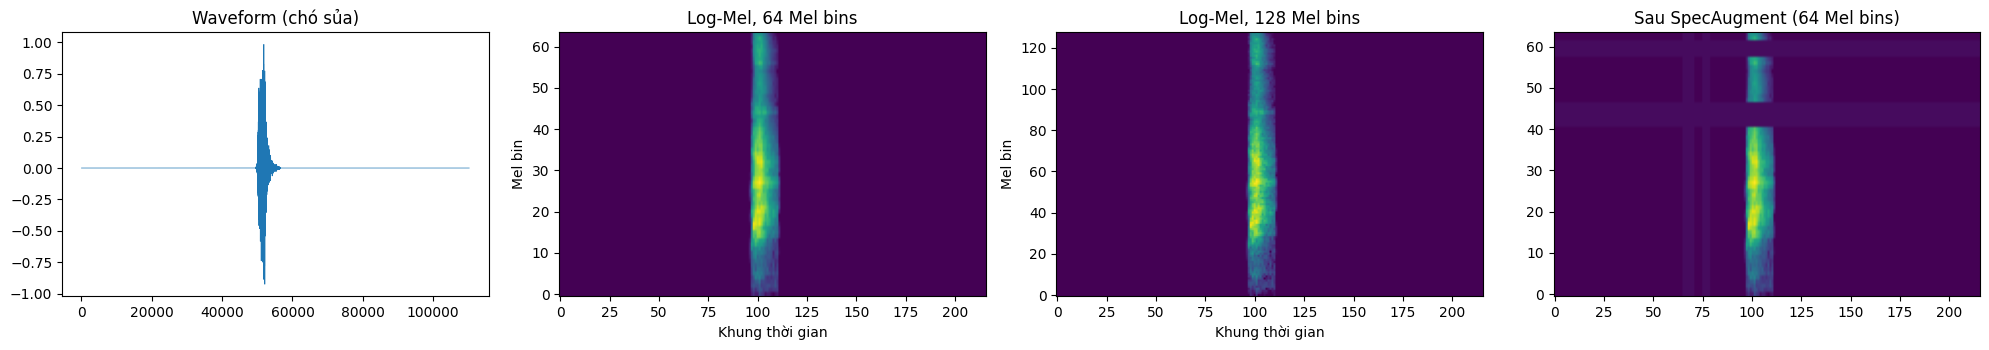

In [9]:
i = int(np.where(meta["category"] == "dog")[0][0])
wav = X[i:i + 1].to(DEVICE)

fig, axes = plt.subplots(1, 4, figsize=(20, 3.6))
axes[0].plot(X[i].numpy(), linewidth=0.5)
axes[0].set_title("Waveform (chó sủa)")

for ax, n in zip(axes[1:3], (64, 128)):
    spec = LogMel(n).to(DEVICE)(wav)[0, 0].cpu().numpy()
    ax.imshow(spec, origin="lower", aspect="auto")
    ax.set_title(f"Log-Mel, {n} Mel bins")
    ax.set_xlabel("Khung thời gian")
    ax.set_ylabel("Mel bin")

s = LogMel(64).to(DEVICE)(wav)
s = (s - s.mean()) / s.std()
aug = SpecAug(64, CFG["FREQ_MASK_RATIO"], CFG["TIME_MASK_PARAM"], CFG["NUM_MASKS"]).to(DEVICE)(s)
axes[3].imshow(aug[0, 0].cpu().numpy(), origin="lower", aspect="auto")
axes[3].set_title("Sau SpecAugment (64 Mel bins)")
plt.tight_layout()
plt.show()

### Phân tích khám phá dữ liệu (EDA)

Phân bố dữ liệu theo nhóm và fold, năng lượng âm thanh theo nhóm, độ dài khoảng lặng được đệm và ví dụ Log-Mel đại diện cho từng nhóm.

fold,1,2,3,4,5,All
Nhóm / Fold,,,,,,
Thiên nhiên và nước,80,80,80,80,80,400
Tiếng ồn đô thị,80,80,80,80,80,400
Âm thanh con người,80,80,80,80,80,400
Âm thanh trong nhà,80,80,80,80,80,400
Động vật,80,80,80,80,80,400
All,400,400,400,400,400,2000


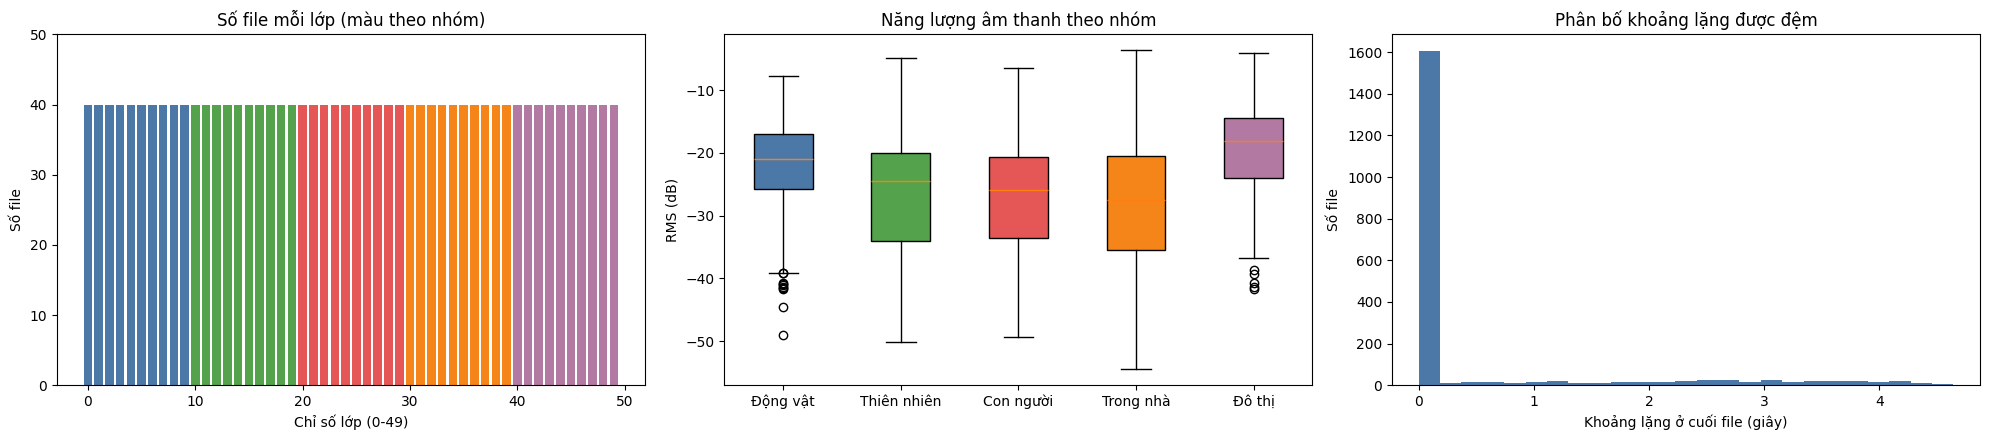

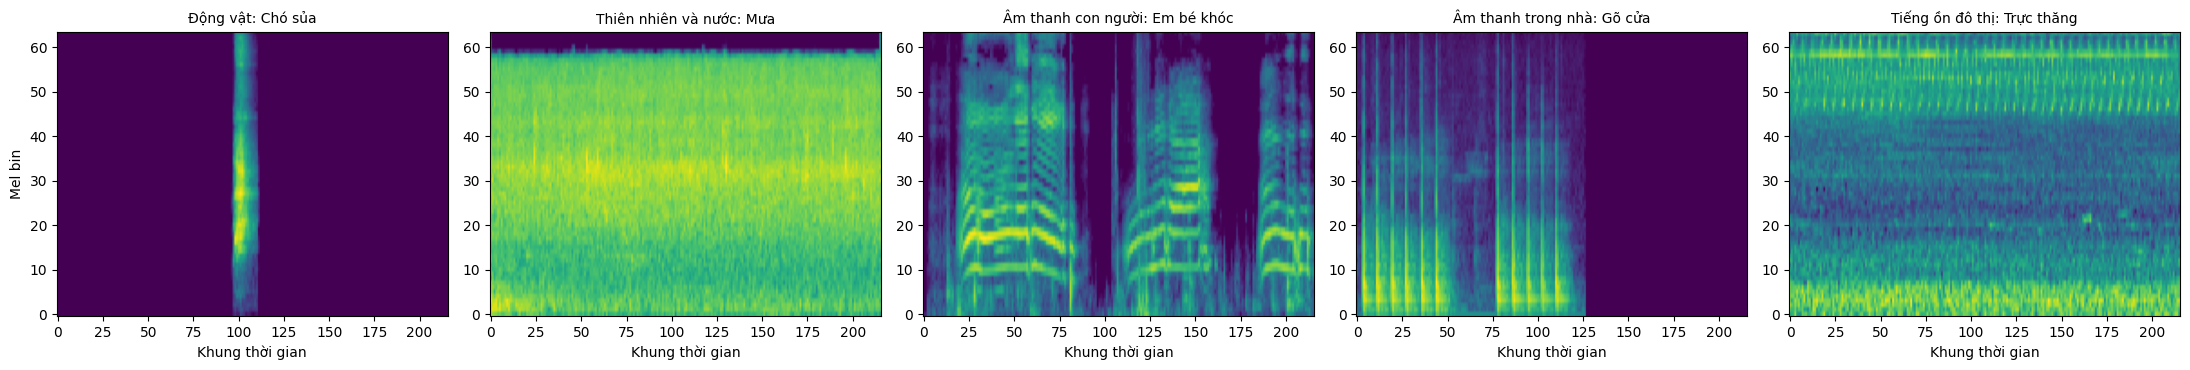

5 lớp có nhiều khoảng lặng được đệm nhất (trung bình, giây):
  Kính vỡ: 2.66
  Hắt hơi: 2.16
  Ho: 1.95
  Gõ cửa: 1.80
  Gà trống gáy: 1.78


In [10]:
meta["group"] = meta["target"] // 10
meta["group_name"] = meta["group"].map(dict(enumerate(GROUP_NAMES)))
meta["pad_sec"] = pad_sec
GROUP_COLORS = ["#4C78A8", "#54A24B", "#E45756", "#F58518", "#B279A2"]
SHORT_GROUPS = ["Động vật", "Thiên nhiên", "Con người", "Trong nhà", "Đô thị"]

display(pd.crosstab(meta["group_name"], meta["fold"], margins=True).rename_axis("Nhóm / Fold"))

rms_db = 20 * np.log10(X.pow(2).mean(dim=1).sqrt().numpy() + 1e-8)

fig, axes = plt.subplots(1, 3, figsize=(20, 4.5))

# (a) số file mỗi lớp, tô màu theo nhóm
counts = meta["target"].value_counts().sort_index()
axes[0].bar(range(50), counts.values, color=[GROUP_COLORS[i // 10] for i in range(50)])
axes[0].set_ylim(0, 50)
axes[0].set_xlabel("Chỉ số lớp (0-49)")
axes[0].set_ylabel("Số file")
axes[0].set_title("Số file mỗi lớp (màu theo nhóm)")

# (b) năng lượng (RMS, dB) theo nhóm
box = axes[1].boxplot([rms_db[meta["group"].values == g] for g in range(5)], patch_artist=True)
for patch, c in zip(box["boxes"], GROUP_COLORS):
    patch.set_facecolor(c)
axes[1].set_xticks(range(1, 6))
axes[1].set_xticklabels(SHORT_GROUPS)
axes[1].set_ylabel("RMS (dB)")
axes[1].set_title("Năng lượng âm thanh theo nhóm")

# (c) khoảng lặng được đệm ở cuối file
axes[2].hist(pad_sec, bins=25, color="#4C78A8")
axes[2].set_xlabel("Khoảng lặng ở cuối file (giây)")
axes[2].set_ylabel("Số file")
axes[2].set_title("Phân bố khoảng lặng được đệm")
plt.tight_layout()
plt.show()

# Ví dụ Log-Mel (64 bins) của mỗi nhóm
fe64 = LogMel(64).to(DEVICE)
fig, axes = plt.subplots(1, 5, figsize=(22, 3.8))
for g, ax in enumerate(axes):
    i = int(np.where(meta["target"].values == g * 10)[0][0])
    spec = fe64(X[i:i + 1].to(DEVICE))[0, 0].cpu().numpy()
    ax.imshow(spec, origin="lower", aspect="auto")
    ax.set_title(f"{GROUP_NAMES[g]}: {VI_LIST[g * 10]}", fontsize=10)
    ax.set_xlabel("Khung thời gian")
axes[0].set_ylabel("Mel bin")
plt.tight_layout()
plt.show()

top_pad = meta.groupby("target")["pad_sec"].mean().sort_values(ascending=False).head(5)
print("5 lớp có nhiều khoảng lặng được đệm nhất (trung bình, giây):")
for t, v in top_pad.items():
    print(f"  {VI_LIST[t]}: {v:.2f}")

## 4. Mô hình CNN và CRNN

- **CNN (baseline):** 4 khối, mỗi khối gồm 2 lớp `Conv2D 3×3 → BatchNorm → ReLU` rồi `MaxPool 2×2` (32 → 64 → 128 → 256 kênh). Đầu ra lấy trung bình theo tần số, rồi max + trung bình theo thời gian, Dropout 0,3, Fully Connected 50.
- **CRNN:** 4 khối tích chập như CNN, nhưng hai khối cuối chỉ pooling theo tần số để giữ thông tin thời gian. Đầu ra được xếp thành chuỗi theo thời gian, đưa qua Bi-GRU (hidden size 128), lấy trung bình theo thời gian, Dropout, Fully Connected 50.

In [11]:
def conv_block(c_in, c_out, pool, n_conv):
    layers = []
    for k in range(n_conv):
        layers += [
            nn.Conv2d(c_in if k == 0 else c_out, c_out, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(c_out),
            nn.ReLU(inplace=True),
        ]
    layers.append(nn.MaxPool2d(pool))
    return nn.Sequential(*layers)


class CNN(nn.Module):
    def __init__(self, n_classes=50, n_conv=2):
        super().__init__()
        self.features = nn.Sequential(
            conv_block(1, 32, (2, 2), n_conv),
            conv_block(32, 64, (2, 2), n_conv),
            conv_block(64, 128, (2, 2), n_conv),
            conv_block(128, 256, (2, 2), n_conv),
        )
        self.drop = nn.Dropout(0.3)
        self.fc = nn.Linear(256, n_classes)

    def forward(self, x):                  # x: (B, 1, n_mels, T)
        x = self.features(x)               # (B, C, F', T')
        x = x.mean(dim=2)                  # trung bình theo tần số
        x = x.max(dim=2).values + x.mean(dim=2)   # max + trung bình theo thời gian
        return self.fc(self.drop(x))


class CRNN(nn.Module):
    def __init__(self, n_mels, n_classes=50, n_conv=2, hidden=128):
        super().__init__()
        self.features = nn.Sequential(
            conv_block(1, 32, (2, 2), n_conv),
            conv_block(32, 64, (2, 2), n_conv),
            conv_block(64, 128, (2, 1), n_conv),   # chỉ pooling theo tần số
            conv_block(128, 256, (2, 1), n_conv),  # chỉ pooling theo tần số
        )
        freq_out = n_mels // 16
        self.gru = nn.GRU(256 * freq_out, hidden, batch_first=True, bidirectional=True)
        self.drop = nn.Dropout(0.3)
        self.fc = nn.Linear(hidden * 2, n_classes)

    def forward(self, x):
        x = self.features(x)                              # (B, C, F', T')
        b, c, f, t = x.shape
        x = x.permute(0, 3, 1, 2).reshape(b, t, c * f)    # chuỗi theo thời gian
        x, _ = self.gru(x)
        x = x.mean(dim=1)
        return self.fc(self.drop(x))


def build_model(name, n_mels, n_conv=None):
    n_conv = n_conv or CFG["CONV_PER_BLOCK"]
    n_classes = CFG["NUM_CLASSES"]
    return CNN(n_classes, n_conv) if name == "cnn" else CRNN(n_mels, n_classes, n_conv)


def count_params(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


# Kiểm tra nhanh kích thước đầu ra và số tham số
n_frames = TARGET_LEN // CFG["HOP_LENGTH"] + 1
for name in ("cnn", "crnn"):
    for n in (64, 128):
        m = build_model(name, n).to(DEVICE).eval()
        with torch.no_grad():
            out = m(torch.randn(2, 1, n, n_frames, device=DEVICE))
        print(f"{name.upper():5s} | {n:3d} Mel bins | output {tuple(out.shape)} | {count_params(m):,} tham số")

CNN   |  64 Mel bins | output (2, 50) | 1,185,490 tham số
CNN   | 128 Mel bins | output (2, 50) | 1,185,490 tham số
CRNN  |  64 Mel bins | output (2, 50) | 2,071,762 tham số
CRNN  | 128 Mel bins | output (2, 50) | 2,858,194 tham số


## 5. Hàm huấn luyện và đánh giá

- Chia dữ liệu: mỗi lần lặp dùng 1 fold làm test, fold kế tiếp (quay vòng) làm validation, 3 fold còn lại để huấn luyện.
- Huấn luyện từ đầu bằng AdamW + Cosine Annealing, Cross-Entropy Loss (label smoothing 0,1). Dừng sớm khi Macro-F1 trên validation không tăng sau 15 epoch, giữ lại mô hình tốt nhất trên validation.
- Augmentation cơ bản trên waveform (dịch vòng theo thời gian, đổi âm lượng ±6 dB) được dùng chung cho cả 8 cấu hình, nên SpecAugment vẫn là yếu tố duy nhất thay đổi giữa các cặp so sánh RQ3. Đặt `BASE_AUG = False` trong `CFG` nếu muốn tắt.
- Fold test chỉ dùng để chấm điểm cuối, không dùng để chọn mô hình hay chỉnh cài đặt.

In [12]:
def get_split(test_fold):
    val_fold = test_fold % 5 + 1
    test_idx = np.where(folds == test_fold)[0]
    val_idx = np.where(folds == val_fold)[0]
    train_idx = np.where((folds != test_fold) & (folds != val_fold))[0]
    return train_idx, val_idx, test_idx


class BatchLoader:
    # Lấy batch trực tiếp từ tensor (nằm sẵn trên GPU nếu đủ VRAM), không qua DataLoader/Subset
    # nên không bị nghẽn ở CPU. Nhãn luôn giữ trên CPU.
    def __init__(self, src, labels, idx, batch_size, shuffle):
        self.src, self.labels = src, labels
        self.idx = torch.as_tensor(np.asarray(idx), dtype=torch.long)
        self.bs, self.shuffle = batch_size, shuffle

    def __len__(self):
        return (len(self.idx) + self.bs - 1) // self.bs

    def __iter__(self):
        order = self.idx[torch.randperm(len(self.idx))] if self.shuffle else self.idx
        for i in range(0, len(order), self.bs):
            b = order[i:i + self.bs]
            yield self.src[b.to(self.src.device)], self.labels[b]


def make_loader(idx, batch_size, shuffle, src=None):
    return BatchLoader(X_DEV if src is None else src, y, idx, batch_size, shuffle)


def scores(y_true, y_pred):
    acc = accuracy_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred, average="macro",
                  labels=list(range(CFG["NUM_CLASSES"])), zero_division=0)
    return acc, f1


@torch.no_grad()
def predict(model, frontend, mean, std, loader, snr_db=None, seed=0):
    # snr_db=None: dữ liệu sạch; ngược lại thêm nhiễu Gaussian theo SNR đó
    model.eval()
    gen = torch.Generator(device=DEVICE)
    gen.manual_seed(seed)
    ys, ps = [], []
    for wav, yb in loader:
        wav = wav.to(DEVICE, non_blocking=True)
        if snr_db is not None:
            wav = add_noise(wav, snr_db, gen)
        x = (frontend(wav) - mean) / std
        with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
            out = model(x)
        ps.append(out.argmax(dim=1).cpu().numpy())
        ys.append(yb.numpy())
    return np.concatenate(ys), np.concatenate(ps)


def train_model(model_name, n_mels, use_specaug, train_idx, val_idx, cfg, verbose=True, desc=""):
    frontend = LogMel(n_mels).to(DEVICE)
    mean, std = compute_stats(frontend, train_idx)      # chỉ tính trên tập huấn luyện
    model = build_model(model_name, n_mels).to(DEVICE)
    specaug = (SpecAug(n_mels, cfg["FREQ_MASK_RATIO"], cfg["TIME_MASK_PARAM"],
                       cfg["NUM_MASKS"]).to(DEVICE) if use_specaug else None)

    optimizer = torch.optim.AdamW(model.parameters(), lr=cfg["LR"],
                                  weight_decay=cfg["WEIGHT_DECAY"])
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=cfg["EPOCHS"])
    criterion = nn.CrossEntropyLoss(label_smoothing=cfg["LABEL_SMOOTHING"])
    scaler = torch.amp.GradScaler(DEVICE.type, enabled=USE_AMP)

    train_loader = make_loader(train_idx, cfg["BATCH_SIZE"], shuffle=True)
    val_loader = make_loader(val_idx, 64, shuffle=False)

    best = dict(f1=-1.0, epoch=0, state=None)
    bad_epochs = 0
    history = []

    pbar = tqdm(range(1, cfg["EPOCHS"] + 1), desc=desc or "train", leave=False)
    for epoch in pbar:
        model.train()
        loss_sum, n_seen = 0.0, 0
        for wav, yb in train_loader:
            wav, yb = wav.to(DEVICE, non_blocking=True), yb.to(DEVICE, non_blocking=True)
            with torch.no_grad():
                if cfg["BASE_AUG"]:
                    wav = base_augment(wav, cfg)
                x = (frontend(wav) - mean) / std
                if specaug is not None:
                    x = specaug(x)
            with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
                loss = criterion(model(x), yb)
            optimizer.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
            loss_sum += loss.item() * len(yb)
            n_seen += len(yb)
        scheduler.step()

        yt, yp = predict(model, frontend, mean, std, val_loader)
        val_acc, val_f1 = scores(yt, yp)
        history.append(dict(epoch=epoch, loss=loss_sum / n_seen, val_acc=val_acc, val_f1=val_f1))
        pbar.set_postfix(loss=f"{loss_sum / n_seen:.3f}", val_f1=f"{val_f1:.3f}",
                         best=f"{max(best['f1'], val_f1):.3f}", bad=bad_epochs)
        if verbose:
            print(f"Epoch {epoch:2d} | loss {loss_sum / n_seen:.4f} | val acc {val_acc:.4f} | val F1 {val_f1:.4f}")

        if val_f1 > best["f1"]:
            best.update(f1=val_f1, epoch=epoch,
                        state={k: v.detach().clone() for k, v in model.state_dict().items()})
            bad_epochs = 0
        else:
            bad_epochs += 1
            if bad_epochs >= cfg["PATIENCE"]:
                if verbose:
                    print(f"Dừng sớm tại epoch {epoch}")
                break
    pbar.close()

    model.load_state_dict(best["state"])
    return dict(model=model, frontend=frontend, mean=mean, std=std,
                best_f1=best["f1"], best_epoch=best["epoch"], history=history)

## 6. Tinh chỉnh siêu tham số (tùy chọn)

Chỉ dựa trên validation, thử trên vài cấu hình đại diện:

- E1, E5: learning rate (1e-3, 3e-4) × batch size (16, 32, 64).
- E3, E7: mức che của SpecAugment (nhỏ, vừa, lớn).

Fold test không được dùng. Đặt `RUN_TUNING = True` ở mục 1 để chạy, rồi cập nhật giá trị tốt nhất vào `CFG` và chạy lại từ mục 1 trước khi sang mục 7.

In [13]:
def tune(exp_id, grid, fold=1):
    train_idx, val_idx, _ = get_split(fold)       # bỏ qua test_idx
    exp = EXPERIMENTS[exp_id]
    rows = []
    for params in grid:
        cfg = {**CFG, **params}
        set_seed(cfg["SEED"])
        out = train_model(exp["model"], exp["n_mels"], exp["specaug"],
                          train_idx, val_idx, cfg, verbose=False)
        rows.append({**params, "val_macro_f1": out["best_f1"], "best_epoch": out["best_epoch"]})
        print(exp_id, params, "->", round(out["best_f1"], 4))
    return pd.DataFrame(rows).sort_values("val_macro_f1", ascending=False)


GRID_LR_BATCH = [dict(LR=lr, BATCH_SIZE=b) for lr in (1e-3, 3e-4) for b in (16, 32, 64)]
GRID_MASK = [dict(FREQ_MASK_RATIO=r, TIME_MASK_PARAM=t)
             for r, t in ((0.08, 10), (0.125, 20), (0.2, 30))]

if RUN_TUNING:
    for e in ("E1", "E5"):
        print(f"\n=== Tinh chỉnh {e}: learning rate và batch size ===")
        display(tune(e, GRID_LR_BATCH))
    for e in ("E3", "E7"):
        print(f"\n=== Tinh chỉnh {e}: mức che SpecAugment ===")
        display(tune(e, GRID_MASK))
else:
    print("Bỏ qua bước tinh chỉnh (RUN_TUNING = False). Dùng thiết lập mặc định trong CFG.")

Bỏ qua bước tinh chỉnh (RUN_TUNING = False). Dùng thiết lập mặc định trong CFG.


## 7. Chạy 8 cấu hình × 5 fold

Tổng cộng 8 × 5 = 40 lượt huấn luyện. Kết quả được lưu sau mỗi lượt vào thư mục `results/` (file CSV, dự đoán trên fold test) và mô hình lưu vào `checkpoints/`. Nếu notebook bị ngắt, chạy lại ô này sẽ tiếp tục từ lượt còn dở, không chạy lại các lượt đã xong.

Với mỗi lượt, mô hình cũng được đánh giá lại trên fold test sau khi thêm nhiễu Gaussian (SNR 20, 10, 0 dB) để kiểm tra độ bền (RQ3). Nhiễu chỉ thêm lúc kiểm tra, không dùng khi huấn luyện.

In [14]:
RUNS_CSV = RESULT_DIR / "runs.csv"
ROB_CSV = RESULT_DIR / "robustness.csv"
runs = pd.read_csv(RUNS_CSV) if RUNS_CSV.exists() else pd.DataFrame()
rob = pd.read_csv(ROB_CSV) if ROB_CSV.exists() else pd.DataFrame()
done = set(zip(runs["exp"], runs["fold"])) if len(runs) else set()


def run_experiment(exp_id, test_fold, cfg=CFG):
    exp = EXPERIMENTS[exp_id]
    train_idx, val_idx, test_idx = get_split(test_fold)
    set_seed(cfg["SEED"] + test_fold)               # cùng seed cho mọi cấu hình trong một fold

    t0 = time.time()
    out = train_model(exp["model"], exp["n_mels"], exp["specaug"],
                      train_idx, val_idx, cfg, verbose=False, desc=f"{exp_id} | fold {test_fold}")
    train_time = time.time() - t0
    pd.DataFrame(out["history"]).to_csv(
        RESULT_DIR / f"history_{exp_id}_fold{test_fold}.csv", index=False)

    model, frontend, mean, std = out["model"], out["frontend"], out["mean"], out["std"]
    test_loader = make_loader(test_idx, 64, shuffle=False)

    yt, yp = predict(model, frontend, mean, std, test_loader)
    acc, f1 = scores(yt, yp)
    np.save(RESULT_DIR / f"pred_{exp_id}_fold{test_fold}.npy", np.stack([yt, yp]))
    torch.save(dict(model=exp["model"], n_mels=exp["n_mels"], state=model.state_dict(),
                    mean=mean, std=std, conv_per_block=cfg["CONV_PER_BLOCK"]),
               CKPT_DIR / f"{exp_id}_fold{test_fold}.pt")

    rob_rows = [dict(exp=exp_id, fold=test_fold, condition="Sạch", acc=acc, macro_f1=f1)]
    for snr in cfg["SNR_LIST"]:
        yt_n, yp_n = predict(model, frontend, mean, std, test_loader, snr_db=snr, seed=cfg["SEED"])
        a, f = scores(yt_n, yp_n)
        rob_rows.append(dict(exp=exp_id, fold=test_fold, condition=f"{snr} dB", acc=a, macro_f1=f))

    row = dict(exp=exp_id, model=exp["model"], n_mels=exp["n_mels"], specaug=exp["specaug"],
               fold=test_fold, acc=acc, macro_f1=f1, params=count_params(model),
               best_epoch=out["best_epoch"], val_f1=out["best_f1"], train_time=train_time)
    return row, rob_rows


todo = [(f, e) for f in FOLDS for e in EXP_IDS if EXPERIMENTS[e]["model"] != "panns"]
print(f"Thiết bị huấn luyện: {DEVICE} ({torch.cuda.get_device_name(0) if DEVICE.type == 'cuda' else 'CPU'})")
print(f"Kế hoạch: {len(EXP_IDS)} cấu hình {EXP_IDS} x {len(FOLDS)} fold = {len(todo)} lượt, "
      f"tối đa {CFG['EPOCHS']} epoch/lượt | đã xong từ trước: {len([t for t in todo if (t[1], t[0]) in done])}")

for fold in FOLDS:
    for exp_id in [e for e in EXP_IDS if EXPERIMENTS[e]["model"] != "panns"]:
        if (exp_id, fold) in done:
            continue
        row, rob_rows = run_experiment(exp_id, fold)
        runs = pd.concat([runs, pd.DataFrame([row])], ignore_index=True)
        rob = pd.concat([rob, pd.DataFrame(rob_rows)], ignore_index=True)
        runs.to_csv(RUNS_CSV, index=False)
        rob.to_csv(ROB_CSV, index=False)
        print(f"[{exp_id} | fold {fold}] acc {row['acc']:.4f} | macro-F1 {row['macro_f1']:.4f} "
              f"| epoch tốt nhất {row['best_epoch']} | {row['train_time']:.0f}s")

print("\nHoàn thành.")

Thiết bị huấn luyện: cuda (NVIDIA GeForce RTX 3080 Laptop GPU)
Kế hoạch: 8 cấu hình ['E1', 'E2', 'E3', 'E4', 'E5', 'E6', 'E7', 'E8'] x 5 fold = 40 lượt, tối đa 80 epoch/lượt | đã xong từ trước: 0


E1 | fold 1:   0%|          | 0/80 [00:00<?, ?it/s]

[E1 | fold 1] acc 0.8175 | macro-F1 0.8124 | epoch tốt nhất 68 | 78s


E2 | fold 1:   0%|          | 0/80 [00:00<?, ?it/s]

[E2 | fold 1] acc 0.8225 | macro-F1 0.8128 | epoch tốt nhất 67 | 127s


E3 | fold 1:   0%|          | 0/80 [00:00<?, ?it/s]

... (71 outputs left out)

E7 | fold 5:   0%|          | 0/80 [00:00<?, ?it/s]

[E7 | fold 5] acc 0.7600 | macro-F1 0.7450 | epoch tốt nhất 68 | 89s


E8 | fold 5:   0%|          | 0/80 [00:00<?, ?it/s]

[E8 | fold 5] acc 0.7825 | macro-F1 0.7653 | epoch tốt nhất 48 | 151s

Hoàn thành.


### 7.1. Mô hình tốt nhất: fine-tune PANNs CNN14 (E9)

Để đạt độ chính xác cao nhất có thể, ngoài 8 cấu hình E1–E8 (huấn luyện từ đầu), notebook fine-tune thêm mô hình **PANNs CNN14** đã được huấn luyện trước trên AudioSet (Kong và cộng sự, 2020). Mô hình này đã học từ hàng triệu đoạn âm thanh nên chỉ cần học lại lớp cuối cho 50 loại của ESC-50, thường cho kết quả cao hơn hẳn mô hình học từ đầu khi dữ liệu ít.

- Dùng cùng cách chia 5 fold (3 train, 1 validation, 1 test) nên so sánh được với E1–E8.
- Âm thanh resample về 32 kHz và Log-Mel 64 bins đúng cấu hình lúc pretrain (n_fft 1024, hop 320).
- Fine-tune toàn bộ mạng: learning rate nhỏ (1e-4) cho phần đã pretrain, lớn hơn (1e-3) cho lớp phân loại mới. Bật SpecAugment và augmentation cơ bản, dùng mixed precision (FP16) khi có GPU.
- Cần internet để tải trọng số (khoảng 330 MB) từ Zenodo và cần GPU NVIDIA (máy không có GPU sẽ tự bỏ qua E9). Đặt `RUN_PANNS = False` nếu muốn bỏ qua phần này.

In [15]:
RUN_PANNS = torch.cuda.is_available() and not QUICK_TEST   # E9 cần GPU NVIDIA; đặt False để bỏ qua
PANNS_CFG = dict(
    SAMPLE_RATE=32000,
    LR_BACKBONE=1e-4, LR_HEAD=1e-3, WEIGHT_DECAY=1e-3,
    BATCH_SIZE=32, EPOCHS=30, PATIENCE=30, LABEL_SMOOTHING=0.1,   # PATIENCE = EPOCHS: chạy đủ 30 epoch
    FREQ_MASK=8, TIME_MASK=64, NUM_MASKS=2,
)
if QUICK_TEST:
    PANNS_CFG["EPOCHS"] = 2
if torch.cuda.is_available() and torch.cuda.get_device_properties(0).total_memory < 8e9:
    PANNS_CFG["BATCH_SIZE"] = 16     # GPU dưới 8 GB VRAM: giảm batch size để tránh thiếu bộ nhớ


class PannsFront(nn.Module):
    # Waveform 32 kHz (B, L) -> Log-Mel (B, 1, 64, T), cấu hình giống lúc pretrain PANNs
    def __init__(self):
        super().__init__()
        self.mel = T.MelSpectrogram(sample_rate=32000, n_fft=1024, win_length=1024,
                                    hop_length=320, f_min=50.0, f_max=14000.0, n_mels=64,
                                    power=2.0, norm="slaney", mel_scale="slaney",
                                    center=True, pad_mode="reflect")
        self.to_db = T.AmplitudeToDB(stype="power", top_db=None)

    def forward(self, wav):
        return self.to_db(self.mel(wav).unsqueeze(1))


class PannsConvBlock(nn.Module):
    def __init__(self, c_in, c_out):
        super().__init__()
        self.conv1 = nn.Conv2d(c_in, c_out, kernel_size=3, stride=1, padding=1, bias=False)
        self.conv2 = nn.Conv2d(c_out, c_out, kernel_size=3, stride=1, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(c_out)
        self.bn2 = nn.BatchNorm2d(c_out)

    def forward(self, x, pool):
        x = F.relu(self.bn1(self.conv1(x)))
        x = F.relu(self.bn2(self.conv2(x)))
        return F.avg_pool2d(x, kernel_size=pool)


class PannsNet(nn.Module):
    # Kiến trúc CNN14 của PANNs, thay lớp đầu ra AudioSet (527 lớp) bằng lớp 50 lớp mới
    def __init__(self, n_classes=50, specaug=None):
        super().__init__()
        self.specaug = specaug
        self.bn0 = nn.BatchNorm2d(64)
        self.conv_block1 = PannsConvBlock(1, 64)
        self.conv_block2 = PannsConvBlock(64, 128)
        self.conv_block3 = PannsConvBlock(128, 256)
        self.conv_block4 = PannsConvBlock(256, 512)
        self.conv_block5 = PannsConvBlock(512, 1024)
        self.conv_block6 = PannsConvBlock(1024, 2048)
        self.fc1 = nn.Linear(2048, 2048)
        self.fc_out = nn.Linear(2048, n_classes)

    def forward(self, x):                                   # x: (B, 1, 64, T)
        x = self.bn0(x.permute(0, 2, 3, 1)).permute(0, 3, 1, 2)   # BatchNorm theo từng Mel bin
        if self.training and self.specaug is not None:
            x = self.specaug(x)
        x = x.transpose(2, 3)                               # (B, 1, T, 64): thời gian là chiều cao
        for block in (self.conv_block1, self.conv_block2, self.conv_block3,
                      self.conv_block4, self.conv_block5):
            x = F.dropout(block(x, (2, 2)), p=0.2, training=self.training)
        x = F.dropout(self.conv_block6(x, (1, 1)), p=0.2, training=self.training)
        x = x.mean(dim=3)                                   # trung bình theo tần số
        x = x.max(dim=2).values + x.mean(dim=2)             # max + trung bình theo thời gian
        x = F.dropout(x, p=0.5, training=self.training)
        x = F.relu(self.fc1(x))
        x = F.dropout(x, p=0.5, training=self.training)
        return self.fc_out(x)

In [16]:
if RUN_PANNS:
    EXPERIMENTS["E9"] = dict(model="panns", n_mels=64, specaug=True)
    if "E9" not in EXP_IDS:
        EXP_IDS.append("E9")

    # Đọc lại toàn bộ âm thanh ở 32 kHz (khoảng 1,3 GB RAM)
    PSR = PANNS_CFG["SAMPLE_RATE"]
    X32 = torch.stack([load_wave(audio_dir / f, PSR) for f in tqdm(meta["filename"])])
    X32_DEV = to_gpu_if_fits(X32)
    print("X32:", tuple(X32.shape), "| nằm trên:", X32_DEV.device)

    # Tải trọng số PANNs CNN14 đã pretrain trên AudioSet
    PANNS_URL = "https://zenodo.org/record/3987831/files/Cnn14_mAP%3D0.431.pth?download=1"
    PANNS_PATH = Path("Cnn14_mAP=0.431.pth")
    if not PANNS_PATH.exists():
        torch.hub.download_url_to_file(PANNS_URL, str(PANNS_PATH))
    panns_state = torch.load(PANNS_PATH, map_location="cpu", weights_only=False)["model"]
    print("Đã nạp trọng số pretrain:", len(panns_state), "tensor")


def load_pretrained(model):
    # Nạp trọng số pretrain; chỉ lớp fc_out (mới) được phép thiếu
    res = model.load_state_dict(panns_state, strict=False)
    missing = [k for k in res.missing_keys if not k.startswith("fc_out")]
    assert not missing, f"Thiếu trọng số pretrain: {missing[:5]}"


def train_panns(train_idx, val_idx, cfg, verbose=False, desc="E9"):
    frontend = PannsFront().to(DEVICE)
    specaug = SpecAug(64, cfg["FREQ_MASK"] / 64, cfg["TIME_MASK"], cfg["NUM_MASKS"]).to(DEVICE)
    model = PannsNet(CFG["NUM_CLASSES"], specaug)
    load_pretrained(model)
    model = model.to(DEVICE)

    head_params = list(model.fc_out.parameters())
    head_ids = {id(p) for p in head_params}
    backbone = [p for p in model.parameters() if id(p) not in head_ids]
    optimizer = torch.optim.AdamW(
        [dict(params=backbone, lr=cfg["LR_BACKBONE"]), dict(params=head_params, lr=cfg["LR_HEAD"])],
        weight_decay=cfg["WEIGHT_DECAY"])
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=cfg["EPOCHS"])
    criterion = nn.CrossEntropyLoss(label_smoothing=cfg["LABEL_SMOOTHING"])
    use_amp = DEVICE.type == "cuda"
    scaler = torch.amp.GradScaler(DEVICE.type, enabled=use_amp)

    train_loader = make_loader(train_idx, cfg["BATCH_SIZE"], True, src=X32_DEV)
    val_loader = make_loader(val_idx, 64, False, src=X32_DEV)

    best = dict(f1=-1.0, epoch=0, state=None)
    bad_epochs = 0
    history = []
    pbar = tqdm(range(1, cfg["EPOCHS"] + 1), desc=desc, leave=False)
    for epoch in pbar:
        model.train()
        loss_sum, n_seen = 0.0, 0
        for wav, yb in train_loader:
            wav, yb = wav.to(DEVICE, non_blocking=True), yb.to(DEVICE, non_blocking=True)
            with torch.no_grad():
                if CFG["BASE_AUG"]:
                    wav = base_augment(wav, CFG)
                x = frontend(wav)
            with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=use_amp):
                loss = criterion(model(x), yb)
            optimizer.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
            loss_sum += loss.item() * len(yb)
            n_seen += len(yb)
        scheduler.step()

        yt, yp = predict(model, frontend, 0.0, 1.0, val_loader)
        val_acc, val_f1 = scores(yt, yp)
        history.append(dict(epoch=epoch, loss=loss_sum / n_seen, val_acc=val_acc, val_f1=val_f1))
        pbar.set_postfix(loss=f"{loss_sum / n_seen:.3f}", val_f1=f"{val_f1:.3f}",
                         best=f"{max(best['f1'], val_f1):.3f}", bad=bad_epochs)
        if verbose:
            print(f"Epoch {epoch:2d} | loss {loss_sum / n_seen:.4f} | val acc {val_acc:.4f} | val F1 {val_f1:.4f}")
        if val_f1 > best["f1"]:
            best.update(f1=val_f1, epoch=epoch,
                        state={k: v.detach().clone() for k, v in model.state_dict().items()})
            bad_epochs = 0
        else:
            bad_epochs += 1
            if bad_epochs >= cfg["PATIENCE"]:
                break
    pbar.close()

    model.load_state_dict(best["state"])
    return dict(model=model, frontend=frontend, best_f1=best["f1"],
                best_epoch=best["epoch"], history=history)


def run_panns(test_fold, cfg=PANNS_CFG):
    train_idx, val_idx, test_idx = get_split(test_fold)
    set_seed(CFG["SEED"] + test_fold)
    t0 = time.time()
    out = train_panns(train_idx, val_idx, cfg, desc=f"E9 | fold {test_fold}")
    train_time = time.time() - t0
    pd.DataFrame(out["history"]).to_csv(RESULT_DIR / f"history_E9_fold{test_fold}.csv", index=False)

    model, frontend = out["model"], out["frontend"]
    test_loader = make_loader(test_idx, 64, False, src=X32_DEV)
    yt, yp = predict(model, frontend, 0.0, 1.0, test_loader)
    acc, f1 = scores(yt, yp)
    np.save(RESULT_DIR / f"pred_E9_fold{test_fold}.npy", np.stack([yt, yp]))
    torch.save(dict(model="panns", n_mels=64, conv_per_block=2, sample_rate=cfg["SAMPLE_RATE"],
                    state={k: (v.cpu().half() if v.is_floating_point() else v.cpu())
                           for k, v in model.state_dict().items()},
                    mean=0.0, std=1.0), CKPT_DIR / f"E9_fold{test_fold}.pt")

    rob_rows = [dict(exp="E9", fold=test_fold, condition="Sạch", acc=acc, macro_f1=f1)]
    for snr in CFG["SNR_LIST"]:
        yt_n, yp_n = predict(model, frontend, 0.0, 1.0, test_loader, snr_db=snr, seed=CFG["SEED"])
        a, f = scores(yt_n, yp_n)
        rob_rows.append(dict(exp="E9", fold=test_fold, condition=f"{snr} dB", acc=a, macro_f1=f))

    row = dict(exp="E9", model="panns", n_mels=64, specaug=True, fold=test_fold, acc=acc,
               macro_f1=f1, params=count_params(model), best_epoch=out["best_epoch"],
               val_f1=out["best_f1"], train_time=train_time)
    return row, rob_rows


if RUN_PANNS:
    for fold in FOLDS:
        if ("E9", fold) in done:
            continue
        row, rob_rows = run_panns(fold)
        runs = pd.concat([runs, pd.DataFrame([row])], ignore_index=True)
        rob = pd.concat([rob, pd.DataFrame(rob_rows)], ignore_index=True)
        runs.to_csv(RUNS_CSV, index=False)
        rob.to_csv(ROB_CSV, index=False)
        print(f"[E9 | fold {fold}] acc {row['acc']:.4f} | macro-F1 {row['macro_f1']:.4f} "
              f"| epoch tốt nhất {row['best_epoch']} | {row['train_time']:.0f}s")
    print("Hoàn thành E9.")

  0%|          | 0/2000 [00:00<?, ?it/s]

X32: (2000, 160000) | nằm trên: cuda:0


100%|██████████| 312M/312M [05:44<00:00, 951kB/s] 


Đã nạp trọng số pretrain: 84 tensor


E9 | fold 1:   0%|          | 0/30 [00:00<?, ?it/s]

[E9 | fold 1] acc 0.9325 | macro-F1 0.9259 | epoch tốt nhất 19 | 214s


... (4 outputs left out)

E9 | fold 4:   0%|          | 0/30 [00:00<?, ?it/s]

[E9 | fold 4] acc 0.9350 | macro-F1 0.9345 | epoch tốt nhất 30 | 200s


E9 | fold 5:   0%|          | 0/30 [00:00<?, ?it/s]

[E9 | fold 5] acc 0.9200 | macro-F1 0.9156 | epoch tốt nhất 26 | 199s
Hoàn thành E9.


## 8. Kết quả

### 8.1. Bảng so sánh Accuracy và Macro-F1 (trung bình ± độ lệch chuẩn qua các fold)

,Mô hình,Mel bins,SpecAugment,Accuracy (%),Macro-F1 (%),Số tham số,Thời gian/lượt (s)
exp,,,,,,,
E1,CNN,64,Tắt,82.10 ± 2.13,81.34 ± 2.30,"1,185,490",74
E2,CNN,128,Tắt,83.60 ± 1.39,83.03 ± 1.61,"1,185,490",123
E3,CNN,64,Bật,83.55 ± 1.81,83.03 ± 2.06,"1,185,490",77
E4,CNN,128,Bật,83.45 ± 2.06,82.90 ± 2.27,"1,185,490",126
E5,CRNN,64,Tắt,75.35 ± 3.30,74.22 ± 3.57,"2,071,762",86
E6,CRNN,128,Tắt,75.30 ± 3.61,74.21 ± 3.84,"2,858,194",147
E7,CRNN,64,Bật,78.15 ± 2.39,77.46 ± 2.52,"2,071,762",90
E8,CRNN,128,Bật,78.25 ± 2.26,77.18 ± 2.28,"2,858,194",151
E9,PANNs CNN14 (pretrained),64,Bật,93.90 ± 1.97,93.64 ± 2.16,"79,776,242",202


Số fold đã chạy: 5


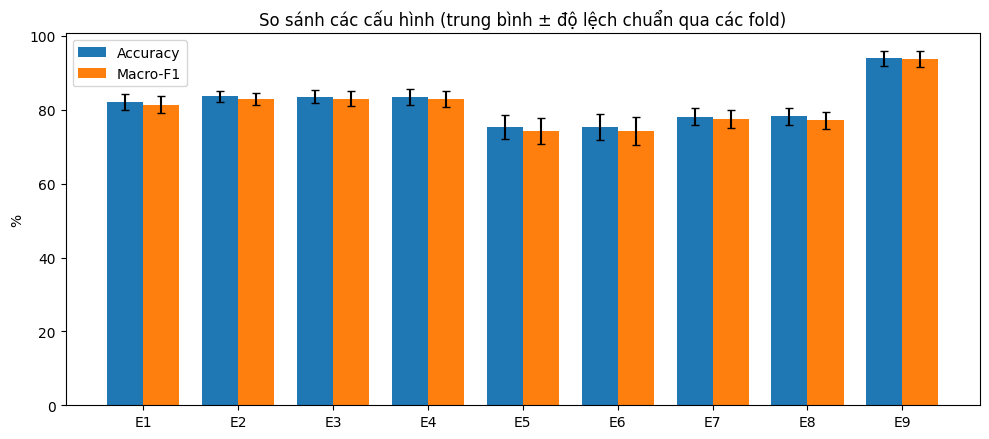

In [17]:
runs = pd.read_csv(RUNS_CSV)
rob = pd.read_csv(ROB_CSV)
FOLDS_DONE = sorted(runs["fold"].unique())

summary = runs.groupby("exp").agg(
    acc_mean=("acc", "mean"), acc_std=("acc", "std"),
    f1_mean=("macro_f1", "mean"), f1_std=("macro_f1", "std"),
    params=("params", "first"), time_mean=("train_time", "mean"),
).reindex([e for e in EXP_IDS if e in runs["exp"].unique()]).fillna(0.0)

table = pd.DataFrame({
    "Mô hình": [{"cnn": "CNN", "crnn": "CRNN", "panns": "PANNs CNN14 (pretrained)"}[EXPERIMENTS[e]["model"]]
                for e in summary.index],
    "Mel bins": [EXPERIMENTS[e]["n_mels"] for e in summary.index],
    "SpecAugment": ["Bật" if EXPERIMENTS[e]["specaug"] else "Tắt" for e in summary.index],
    "Accuracy (%)": [f"{m * 100:.2f} ± {s * 100:.2f}" for m, s in zip(summary.acc_mean, summary.acc_std)],
    "Macro-F1 (%)": [f"{m * 100:.2f} ± {s * 100:.2f}" for m, s in zip(summary.f1_mean, summary.f1_std)],
    "Số tham số": [f"{int(p):,}" for p in summary.params],
    "Thời gian/lượt (s)": [f"{t:.0f}" for t in summary.time_mean],
}, index=summary.index)
display(table)
print("Số fold đã chạy:", len(FOLDS_DONE))

fig, ax = plt.subplots(figsize=(10, 4.5))
x = np.arange(len(summary))
w = 0.38
ax.bar(x - w / 2, summary.acc_mean * 100, w, yerr=summary.acc_std * 100, capsize=3, label="Accuracy")
ax.bar(x + w / 2, summary.f1_mean * 100, w, yerr=summary.f1_std * 100, capsize=3, label="Macro-F1")
ax.set_xticks(x)
ax.set_xticklabels(summary.index)
ax.set_ylabel("%")
ax.set_title("So sánh các cấu hình (trung bình ± độ lệch chuẩn qua các fold)")
ax.legend()
plt.tight_layout()
plt.show()

### 8.2. Kết quả từng fold

In [18]:
runs = pd.read_csv(RUNS_CSV)
ordered = [e for e in EXP_IDS if e in runs["exp"].unique()]

for title, col, fname in (("Accuracy (%)", "acc", "per_fold_accuracy.csv"),
                          ("Macro-F1 (%)", "macro_f1", "per_fold_macro_f1.csv")):
    base = runs.pivot(index="fold", columns="exp", values=col)[ordered]
    table_fold = base * 100
    table_fold.loc["Trung bình"] = base.mean() * 100
    table_fold.loc["Độ lệch chuẩn"] = base.std() * 100
    table_fold.index = [f"Fold {i}" if isinstance(i, (int, np.integer)) else i
                        for i in table_fold.index]
    table_fold.to_csv(RESULT_DIR / fname)
    print(title + " trên từng fold test:")
    display(table_fold.round(2))

Accuracy (%) trên từng fold test:


exp,E1,E2,E3,E4,E5,E6,E7,E8,E9
Fold 1,81.75,82.25,81.00,80.50,74.00,71.50,77.25,76.00,93.25
Fold 2,84.50,83.75,84.75,84.00,79.75,76.25,79.75,80.25,97.25
Fold 3,80.75,82.50,84.00,86.00,76.25,74.25,76.25,76.00,93.50
Fold 4,84.00,85.75,85.50,84.25,76.00,81.00,81.50,80.75,93.50
Fold 5,79.50,83.75,82.50,82.50,70.75,73.50,76.00,78.25,92.00
Trung bình,82.10,83.60,83.55,83.45,75.35,75.30,78.15,78.25,93.90
Độ lệch chuẩn,2.13,1.39,1.81,2.06,3.30,3.61,2.39,2.26,1.97


Macro-F1 (%) trên từng fold test:


exp,E1,E2,E3,E4,E5,E6,E7,E8,E9
Fold 1,81.24,81.28,80.09,79.90,73.54,69.94,77.00,74.97,92.59
Fold 2,83.71,83.36,84.07,83.59,78.90,75.33,78.79,79.17,97.25
Fold 3,80.14,82.25,83.60,85.77,74.82,73.74,76.01,75.24,93.35
Fold 4,83.40,85.58,85.43,83.78,74.89,80.07,80.99,79.96,93.45
Fold 5,78.20,82.68,81.97,81.44,68.94,71.97,74.50,76.53,91.56
Trung bình,81.34,83.03,83.03,82.90,74.22,74.21,77.46,77.18,93.64
Độ lệch chuẩn,2.30,1.61,2.06,2.27,3.57,3.84,2.52,2.28,2.16


### 8.3. Đường học (learning curves)

Trung bình qua các fold của loss huấn luyện, Accuracy và Macro-F1 trên validation theo từng epoch. Nét liền: bật SpecAugment, nét đứt: tắt. Loss huấn luyện khi bật SpecAugment thường cao hơn vì ảnh đầu vào bị che ngẫu nhiên. Ở các epoch cuối, đường chỉ tính trên những fold chưa dừng sớm.

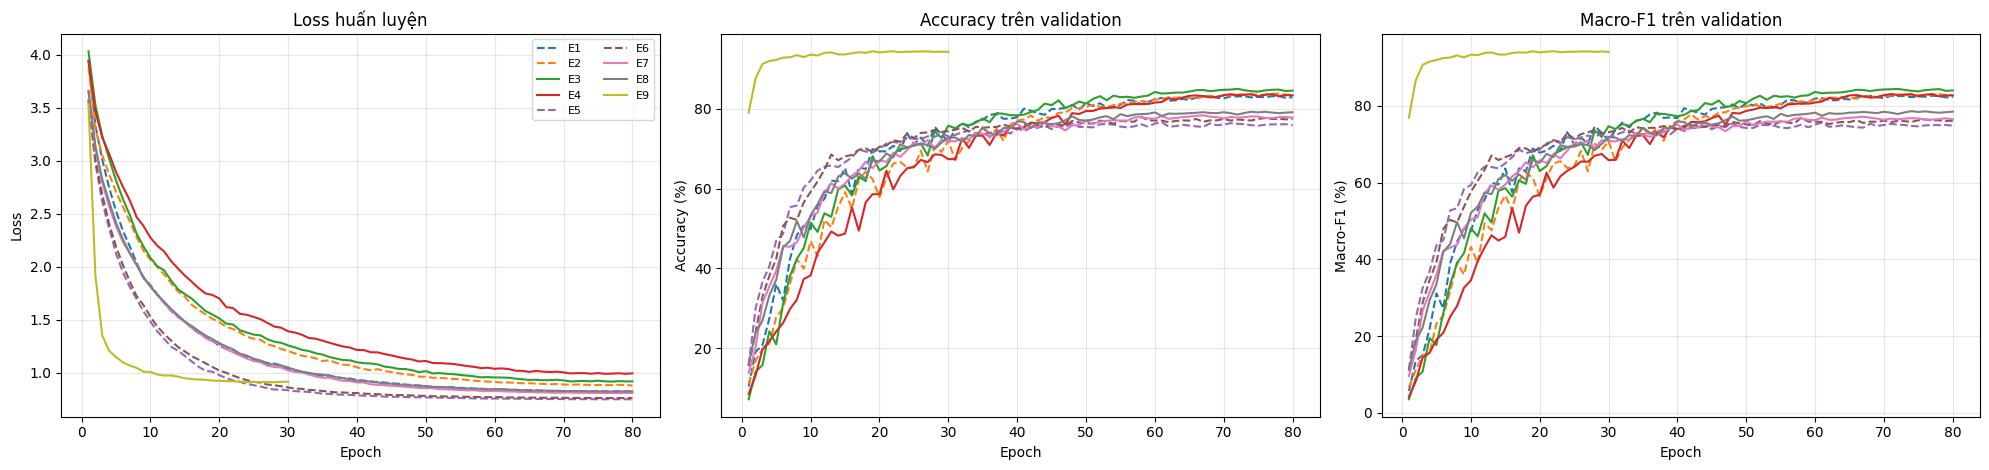

,Epoch tốt nhất (trung bình),Nhỏ nhất,Lớn nhất
exp,,,
E1,69.6,66,74
E2,69.6,58,78
E3,69.4,61,78
E4,73.6,66,80
E5,57.4,48,72
E6,61.4,49,76
E7,65.0,59,75
E8,60.4,48,71
E9,24.4,19,30


In [19]:
frames = []
for e in ordered:
    for f in sorted(runs["fold"].unique()):
        p = RESULT_DIR / f"history_{e}_fold{f}.csv"
        if p.exists():
            h = pd.read_csv(p)
            h["exp"], h["fold"] = e, f
            frames.append(h)

if frames:
    hist = pd.concat(frames, ignore_index=True)
    fig, axes = plt.subplots(1, 3, figsize=(20, 4.8))
    for e in ordered:
        g = hist[hist["exp"] == e].groupby("epoch")[["loss", "val_acc", "val_f1"]].mean()
        if g.empty:
            continue
        style = "-" if EXPERIMENTS[e]["specaug"] else "--"
        axes[0].plot(g.index, g["loss"], style, label=e)
        axes[1].plot(g.index, g["val_acc"] * 100, style, label=e)
        axes[2].plot(g.index, g["val_f1"] * 100, style, label=e)
    for ax, title, ylabel in zip(axes,
                                 ("Loss huấn luyện", "Accuracy trên validation", "Macro-F1 trên validation"),
                                 ("Loss", "Accuracy (%)", "Macro-F1 (%)")):
        ax.set_title(title)
        ax.set_xlabel("Epoch")
        ax.set_ylabel(ylabel)
        ax.grid(alpha=0.3)
    axes[0].legend(ncol=2, fontsize=8)
    plt.tight_layout()
    plt.show()
else:
    print("Không tìm thấy file lịch sử huấn luyện (history_*.csv) trong thư mục kết quả.")

best_ep = runs.groupby("exp")["best_epoch"].agg(["mean", "min", "max"]).reindex(ordered).round(1)
best_ep.columns = ["Epoch tốt nhất (trung bình)", "Nhỏ nhất", "Lớn nhất"]
display(best_ep)

### 8.4. Trả lời RQ1, RQ2, RQ3

Mỗi câu hỏi được trả lời bằng cách so sánh các cặp cấu hình chỉ khác nhau ở một yếu tố. Cột Δ là hiệu số (cấu hình sau trừ cấu hình trước), tính trung bình qua các fold. Kiểm định cặp (paired t-test, Wilcoxon) chỉ mang tính tham khảo vì chỉ có tối đa 5 fold.

In [20]:
RQ_PAIRS = {
    "RQ1: CRNN so với CNN":        [("E1", "E5"), ("E2", "E6"), ("E3", "E7"), ("E4", "E8")],
    "RQ2: 128 so với 64 Mel bins": [("E1", "E2"), ("E3", "E4"), ("E5", "E6"), ("E7", "E8")],
    "RQ3: bật so với tắt SpecAugment": [("E1", "E3"), ("E2", "E4"), ("E5", "E7"), ("E6", "E8")],
}
piv_f1 = runs.pivot(index="fold", columns="exp", values="macro_f1")
piv_acc = runs.pivot(index="fold", columns="exp", values="acc")

rows = []
for rq, pairs in RQ_PAIRS.items():
    for a, b in pairs:
        if a not in piv_f1.columns or b not in piv_f1.columns:
            continue
        pair_f1 = piv_f1[[a, b]].dropna()
        d_f1 = pair_f1[b] - pair_f1[a]
        d_acc = (piv_acc[b] - piv_acc[a]).dropna()
        p_t = p_w = np.nan
        if len(pair_f1) >= 2:
            p_t = stats.ttest_rel(pair_f1[b], pair_f1[a]).pvalue
            try:
                p_w = stats.wilcoxon(d_f1).pvalue
            except ValueError:
                p_w = np.nan
        rows.append({"Câu hỏi": rq, "So sánh": f"{a} → {b}",
                     "Δ Accuracy (điểm %)": round(d_acc.mean() * 100, 2),
                     "Δ Macro-F1 (điểm %)": round(d_f1.mean() * 100, 2),
                     "p (t-test)": round(p_t, 4) if not np.isnan(p_t) else None,
                     "p (Wilcoxon)": round(p_w, 4) if not np.isnan(p_w) else None})

rq_table = pd.DataFrame(rows)
display(rq_table)

for rq in RQ_PAIRS:
    sub = rq_table[rq_table["Câu hỏi"] == rq]
    if len(sub):
        print(f"{rq}: Δ Macro-F1 trung bình = {sub['Δ Macro-F1 (điểm %)'].mean():+.2f} điểm %")

,Câu hỏi,So sánh,Δ Accuracy (điểm %),Δ Macro-F1 (điểm %),p (t-test),p (Wilcoxon)
0,RQ1: CRNN so với CNN,E1 → E5,-6.75,-7.12,0.0013,0.0625
1,RQ1: CRNN so với CNN,E2 → E6,-8.30,-8.82,0.0011,0.0625
2,RQ1: CRNN so với CNN,E3 → E7,-5.40,-5.57,0.0031,0.0625
3,RQ1: CRNN so với CNN,E4 → E8,-5.20,-5.72,0.0094,0.0625
4,RQ2: 128 so với 64 Mel bins,E1 → E2,1.50,1.69,0.1228,0.1875
5,RQ2: 128 so với 64 Mel bins,E3 → E4,-0.10,-0.14,0.8397,0.6250
6,RQ2: 128 so với 64 Mel bins,E5 → E6,-0.05,-0.01,0.9965,1.0000
7,RQ2: 128 so với 64 Mel bins,E7 → E8,0.10,-0.28,0.7042,0.8125
8,RQ3: bật so với tắt SpecAugment,E1 → E3,1.45,1.70,0.1427,0.1875
9,RQ3: bật so với tắt SpecAugment,E2 → E4,-0.15,-0.13,0.8974,0.8125


RQ1: CRNN so với CNN: Δ Macro-F1 trung bình = -6.81 điểm %
RQ2: 128 so với 64 Mel bins: Δ Macro-F1 trung bình = +0.31 điểm %
RQ3: bật so với tắt SpecAugment: Δ Macro-F1 trung bình = +1.94 điểm %


### 8.5. Độ bền khi âm thanh bị thêm nhiễu (RQ3)

condition,Sạch,20 dB,10 dB,0 dB
Accuracy (%) theo mức nhiễu,,,,
E1,82.10,70.85,45.80,9.10
E2,83.60,72.10,44.95,8.40
E3,83.55,72.25,49.00,11.55
E4,83.45,71.15,46.35,9.95
E5,75.35,63.50,38.60,8.95
E6,75.30,62.90,37.15,8.85
E7,78.15,62.75,36.70,8.90
E8,78.25,64.35,39.65,9.95
E9,93.90,90.30,80.55,51.20


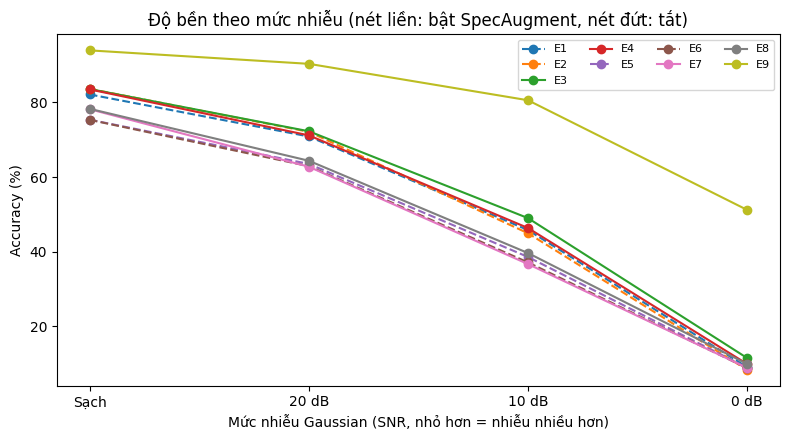

Mức giảm Accuracy từ dữ liệu sạch đến SNR 0 dB (điểm %):
  E1 (tắt): -73.00 | E3 (bật): -72.00
  E2 (tắt): -75.20 | E4 (bật): -73.50
  E5 (tắt): -66.40 | E7 (bật): -69.25
  E6 (tắt): -66.45 | E8 (bật): -68.30


In [21]:
COND_ORDER = ["Sạch", "20 dB", "10 dB", "0 dB"]
rob_acc = rob.groupby(["exp", "condition"])["acc"].mean().unstack()[COND_ORDER]
rob_acc = rob_acc.reindex([e for e in EXP_IDS if e in rob_acc.index])
display((rob_acc * 100).round(2).rename_axis("Accuracy (%) theo mức nhiễu"))

fig, ax = plt.subplots(figsize=(8, 4.5))
for e in rob_acc.index:
    style = "-" if EXPERIMENTS[e]["specaug"] else "--"
    ax.plot(COND_ORDER, rob_acc.loc[e] * 100, style, marker="o", label=e)
ax.set_ylabel("Accuracy (%)")
ax.set_xlabel("Mức nhiễu Gaussian (SNR, nhỏ hơn = nhiễu nhiều hơn)")
ax.set_title("Độ bền theo mức nhiễu (nét liền: bật SpecAugment, nét đứt: tắt)")
ax.legend(ncol=4, fontsize=8)
plt.tight_layout()
plt.show()

print("Mức giảm Accuracy từ dữ liệu sạch đến SNR 0 dB (điểm %):")
for a, b in RQ_PAIRS["RQ3: bật so với tắt SpecAugment"]:
    if a in rob_acc.index and b in rob_acc.index:
        drop_a = (rob_acc.loc[a, "Sạch"] - rob_acc.loc[a, "0 dB"]) * 100
        drop_b = (rob_acc.loc[b, "Sạch"] - rob_acc.loc[b, "0 dB"]) * 100
        print(f"  {a} (tắt): -{drop_a:.2f} | {b} (bật): -{drop_b:.2f}")

### 8.6. Confusion matrix và các cặp lớp hay bị nhầm lẫn

Cấu hình dùng để phân tích: E9


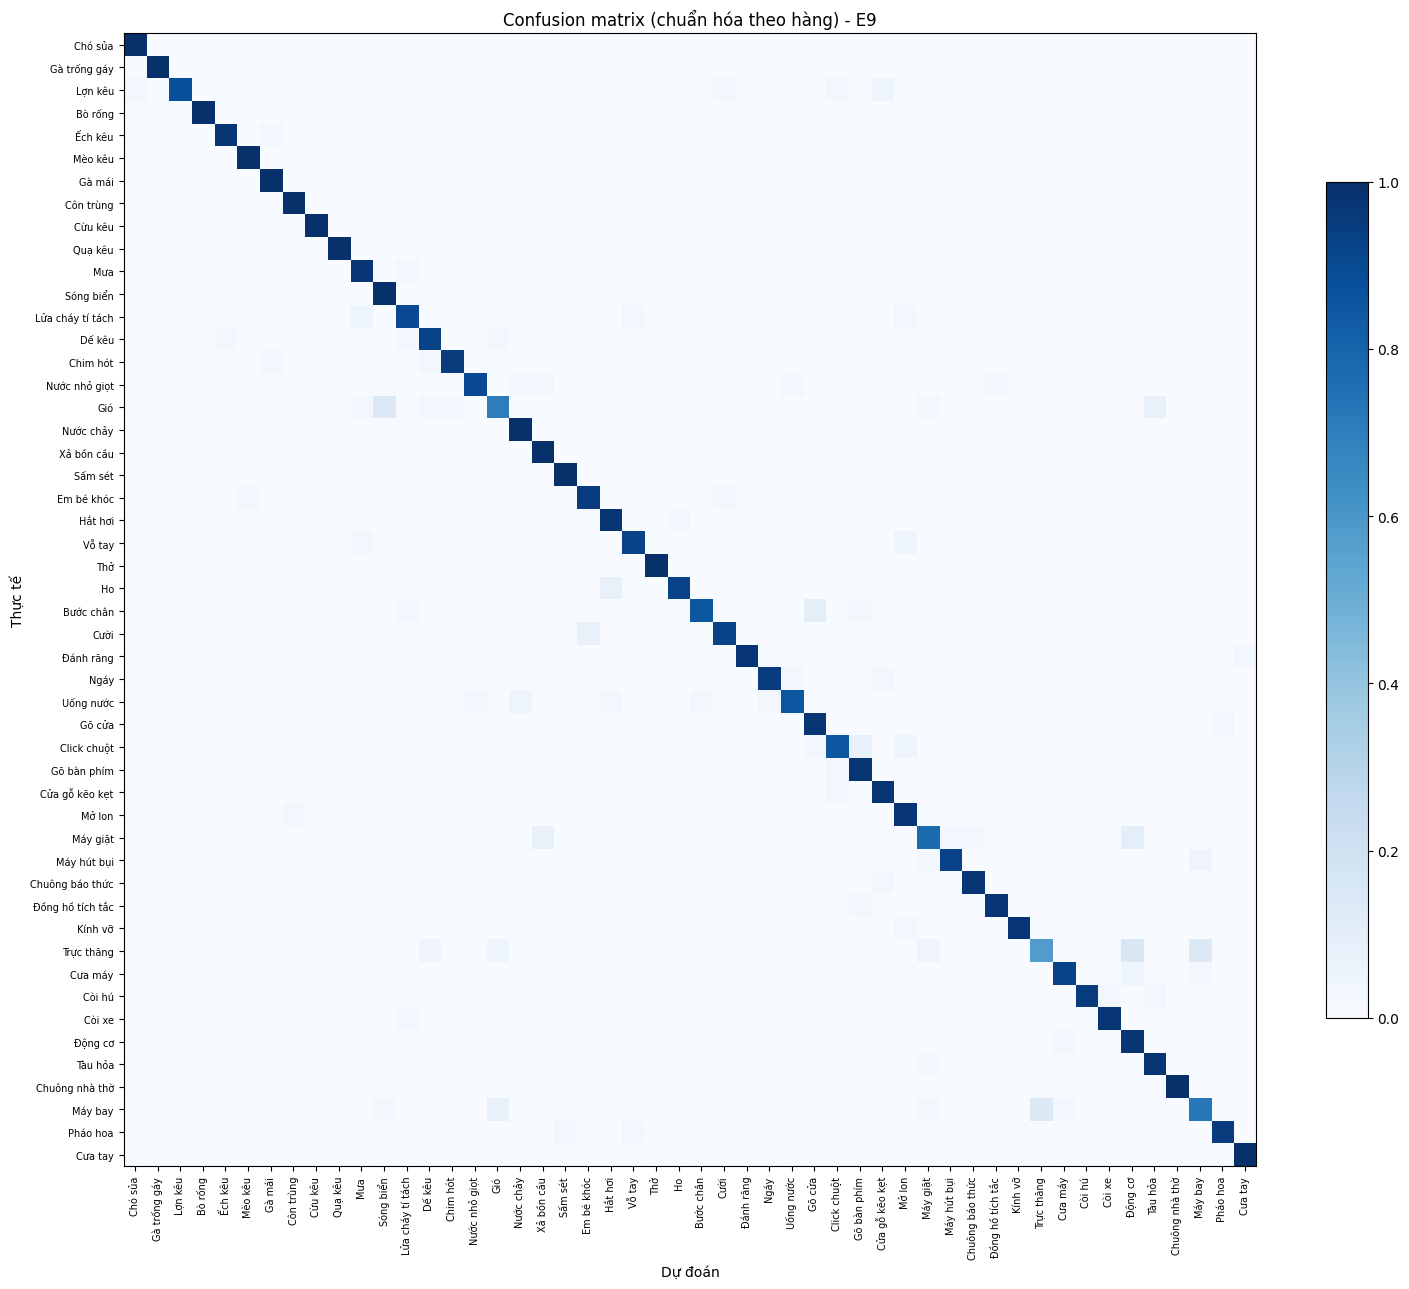


10 cặp hay bị nhầm nhất (thực tế → dự đoán):
  Trực thăng           → Động cơ             : 6 lần
  Máy bay              → Trực thăng          : 5 lần
  Trực thăng           → Máy bay             : 5 lần
  Gió                  → Sóng biển           : 5 lần
  Bước chân            → Gõ cửa              : 4 lần
  Máy giặt             → Động cơ             : 4 lần
  Máy bay              → Gió                 : 3 lần
  Máy giặt             → Xả bồn cầu          : 3 lần
  Click chuột          → Gõ bàn phím         : 3 lần
  Cười                 → Em bé khóc          : 3 lần

Độ chính xác khi chỉ xét 5 nhóm lớn:
  Động vật              : 99.0%
  Thiên nhiên và nước   : 97.5%
  Âm thanh con người    : 96.2%
  Âm thanh trong nhà    : 97.2%
  Tiếng ồn đô thị       : 96.2%

5 lớp có F1 thấp nhất: Trực thăng (0.68), Máy bay (0.75), Gió (0.76), Máy giặt (0.81), Động cơ (0.86)


In [22]:
CM_EXP = None                                   # đặt "E8", ... để chọn cấu hình khác
best_exp = CM_EXP or summary["f1_mean"].idxmax()
print("Cấu hình dùng để phân tích:", best_exp)

yt = np.concatenate([np.load(RESULT_DIR / f"pred_{best_exp}_fold{f}.npy")[0] for f in FOLDS_DONE])
yp = np.concatenate([np.load(RESULT_DIR / f"pred_{best_exp}_fold{f}.npy")[1] for f in FOLDS_DONE])

labels = list(range(CFG["NUM_CLASSES"]))
cm = confusion_matrix(yt, yp, labels=labels)
cm_norm = cm / cm.sum(axis=1, keepdims=True)

fig, ax = plt.subplots(figsize=(15, 13))
im = ax.imshow(cm_norm, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(labels)
ax.set_yticks(labels)
ax.set_xticklabels(VI_LIST, rotation=90, fontsize=7)
ax.set_yticklabels(VI_LIST, fontsize=7)
ax.set_xlabel("Dự đoán")
ax.set_ylabel("Thực tế")
ax.set_title(f"Confusion matrix (chuẩn hóa theo hàng) - {best_exp}")
plt.colorbar(im, fraction=0.03)
plt.tight_layout()
plt.show()

# Các cặp lớp hay bị nhầm nhất
off = cm.copy()
np.fill_diagonal(off, 0)
top = np.dstack(np.unravel_index(np.argsort(-off, axis=None)[:10], off.shape))[0]
print("\n10 cặp hay bị nhầm nhất (thực tế → dự đoán):")
for t, p in top:
    print(f"  {VI_LIST[t]:20s} → {VI_LIST[p]:20s}: {off[t, p]} lần")

# Độ chính xác theo từng nhóm lớn (nhầm trong cùng nhóm vẫn tính là đúng nhóm)
print("\nĐộ chính xác khi chỉ xét 5 nhóm lớn:")
for g, name in enumerate(GROUP_NAMES):
    mask = (yt // 10) == g
    print(f"  {name:22s}: {np.mean((yp[mask] // 10) == g) * 100:.1f}%")

# Các lớp có F1 thấp nhất
per_class_f1 = f1_score(yt, yp, average=None, labels=labels, zero_division=0)
worst = np.argsort(per_class_f1)[:5]
print("\n5 lớp có F1 thấp nhất:", ", ".join(f"{VI_LIST[i]} ({per_class_f1[i]:.2f})" for i in worst))

### 8.7. Precision, Recall và F1 theo từng lớp

10 lớp có F1 thấp nhất:


,Lớp,Nhóm,Precision,Recall,F1
0,Trực thăng,Tiếng ồn đô thị,0.821,0.575,0.676
1,Máy bay,Tiếng ồn đô thị,0.784,0.725,0.753
2,Gió,Thiên nhiên và nước,0.824,0.700,0.757
3,Máy giặt,Âm thanh trong nhà,0.838,0.775,0.805
4,Động cơ,Tiếng ồn đô thị,0.765,0.975,0.857
5,Click chuột,Âm thanh trong nhà,0.919,0.850,0.883
6,Uống nước,Âm thanh con người,0.944,0.850,0.895
7,Lửa cháy tí tách,Thiên nhiên và nước,0.900,0.900,0.900
8,Bước chân,Âm thanh con người,0.971,0.850,0.907
9,Dế kêu,Thiên nhiên và nước,0.902,0.925,0.914


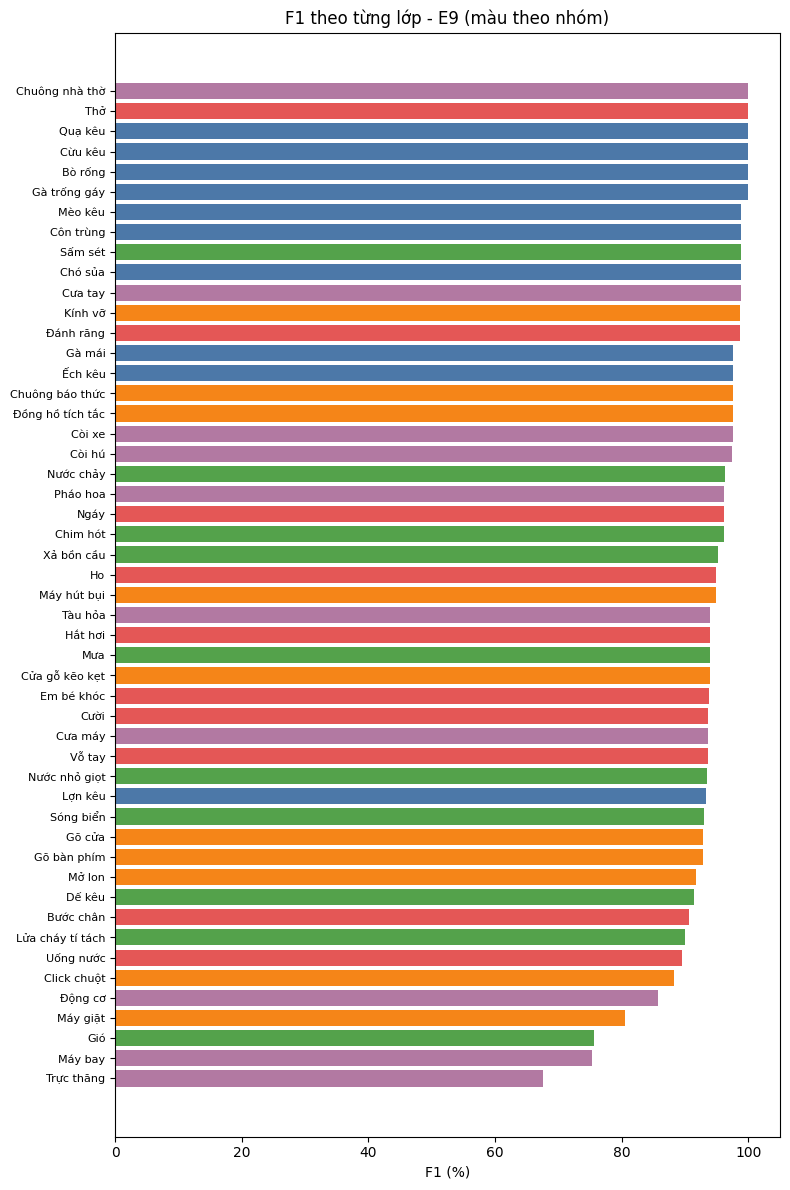

In [23]:
prec, rec, f1c, _ = precision_recall_fscore_support(yt, yp, labels=labels, zero_division=0)
per_class = pd.DataFrame({
    "Lớp": VI_LIST,
    "Nhóm": [GROUP_NAMES[i // 10] for i in labels],
    "Precision": prec, "Recall": rec, "F1": f1c,
}).sort_values("F1").reset_index(drop=True)
per_class.to_csv(RESULT_DIR / f"per_class_{best_exp}.csv", index=False)
print("10 lớp có F1 thấp nhất:")
display(per_class.head(10).round(3))

order = per_class.sort_values("F1")
fig, ax = plt.subplots(figsize=(8, 12))
ax.barh(order["Lớp"], order["F1"] * 100,
        color=[GROUP_COLORS[GROUP_NAMES.index(g)] for g in order["Nhóm"]])
ax.set_xlabel("F1 (%)")
ax.set_title(f"F1 theo từng lớp - {best_exp} (màu theo nhóm)")
ax.tick_params(axis="y", labelsize=8)
plt.tight_layout()
plt.show()

### 8.8. Các mẫu bị dự đoán sai

Chọn ngẫu nhiên một số mẫu trong fold test mà mô hình đoán sai, xem ảnh Log-Mel và nghe lại để hiểu vì sao bị nhầm.

Fold 1 (E9): sai 27/400 mẫu (6.8%)


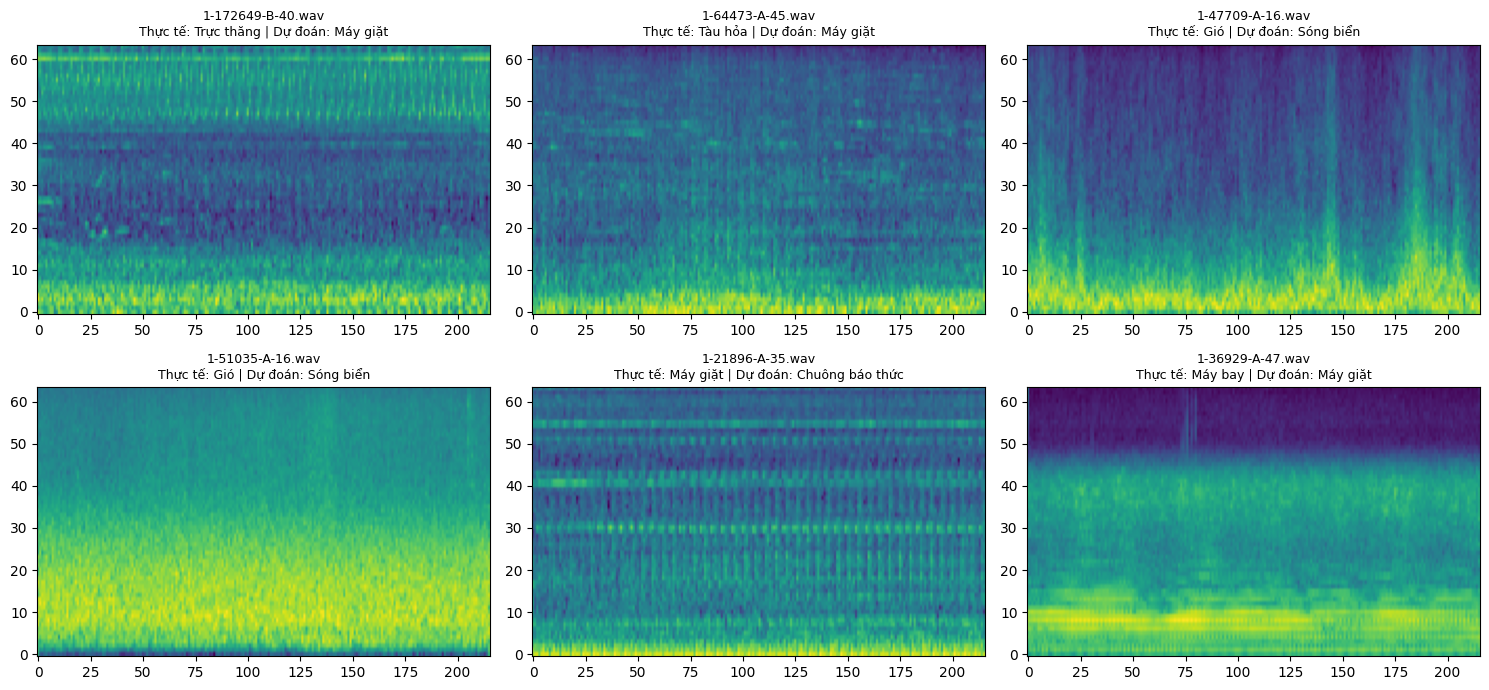

1-172649-B-40.wav | thực tế: Trực thăng | dự đoán: Máy giặt


1-64473-A-45.wav | thực tế: Tàu hỏa | dự đoán: Máy giặt


1-47709-A-16.wav | thực tế: Gió | dự đoán: Sóng biển


In [24]:
EX_FOLD = FOLDS_DONE[0]
_, _, te_idx = get_split(EX_FOLD)
yt_f, yp_f = np.load(RESULT_DIR / f"pred_{best_exp}_fold{EX_FOLD}.npy")
assert (y[te_idx].numpy() == yt_f).all()           # đúng thứ tự với fold test
wrong = np.where(yt_f != yp_f)[0]
print(f"Fold {EX_FOLD} ({best_exp}): sai {len(wrong)}/{len(yt_f)} mẫu ({len(wrong) / len(yt_f):.1%})")

if len(wrong) > 0:
    from IPython.display import Audio
    pick = np.random.RandomState(0).choice(wrong, size=min(6, len(wrong)), replace=False)
    fe = LogMel(EXPERIMENTS[best_exp]["n_mels"]).to(DEVICE)
    fig, axes = plt.subplots(2, 3, figsize=(15, 7))
    for ax, k in zip(axes.ravel(), pick):
        i = te_idx[k]
        spec = fe(X[i:i + 1].to(DEVICE))[0, 0].cpu().numpy()
        ax.imshow(spec, origin="lower", aspect="auto")
        ax.set_title(f"{meta['filename'][i]}\nThực tế: {VI_LIST[yt_f[k]]} | Dự đoán: {VI_LIST[yp_f[k]]}",
                     fontsize=9)
    for ax in axes.ravel()[len(pick):]:
        ax.axis("off")
    plt.tight_layout()
    plt.show()

    for k in pick[:3]:
        i = te_idx[k]
        print(f"{meta['filename'][i]} | thực tế: {VI_LIST[yt_f[k]]} | dự đoán: {VI_LIST[yp_f[k]]}")
        display(Audio(X[i].numpy(), rate=SR))

## 9. Demo: tải lên, xử lý, phân loại, trả kết quả

Demo dùng mô hình đã huấn luyện và lưu sẵn (không huấn luyện lại). Với mỗi file người dùng tải lên:

1. **Tải lên:** chọn một file âm thanh.
2. **Xử lý:** đổi về mono, 22.050 Hz, đúng 5 giây, tính Log-Mel và chuẩn hóa (giống phần tiền xử lý).
3. **Phân loại:** mô hình tính xác suất cho 50 loại.
4. **Trả kết quả:** loại dự đoán, nhóm của loại đó và 3 loại có xác suất cao nhất. Nếu xác suất cao nhất thấp hơn ngưỡng 50% thì báo **Không xác định**.

Kết quả của demo là dự đoán của mô hình nên có thể sai. File dài hơn 5 giây chỉ lấy 5 giây đầu.

In [25]:
DEMO_EXP = best_exp                 # đổi thành "E8", ... nếu muốn dùng cấu hình khác
DEMO_FOLD = FOLDS_DONE[0]
THRESHOLD = 0.5                     # dưới ngưỡng này thì báo "Không xác định"

ckpt = torch.load(CKPT_DIR / f"{DEMO_EXP}_fold{DEMO_FOLD}.pt", map_location=DEVICE, weights_only=False)
DEMO_SR = ckpt.get("sample_rate", SR)
if ckpt["model"] == "panns":
    demo_model = PannsNet(CFG["NUM_CLASSES"]).to(DEVICE)
    demo_frontend = PannsFront().to(DEVICE)
else:
    demo_model = build_model(ckpt["model"], ckpt["n_mels"], ckpt.get("conv_per_block", 1)).to(DEVICE)
    demo_frontend = LogMel(ckpt["n_mels"]).to(DEVICE)
demo_model.load_state_dict(ckpt["state"])
demo_model.eval()
DEMO_MEAN, DEMO_STD = ckpt["mean"], ckpt["std"]
print(f"Đã nạp mô hình {DEMO_EXP} (fold {DEMO_FOLD}).")


@torch.no_grad()
def classify(audio_path):
    if audio_path is None:
        return "Hãy tải lên một file âm thanh.", {}
    wav = load_wave(audio_path, DEMO_SR).unsqueeze(0).to(DEVICE)   # bước 2: xử lý
    x = (demo_frontend(wav) - DEMO_MEAN) / DEMO_STD
    probs = torch.softmax(demo_model(x), dim=1)[0].cpu()           # bước 3: phân loại
    top_p, top_i = probs.topk(3)
    best_i, best_p = int(top_i[0]), float(top_p[0])

    if best_p < THRESHOLD:                                         # bước 4: trả kết quả
        message = f"Không xác định (xác suất cao nhất chỉ {best_p:.0%})"
    else:
        message = f"Kết quả: {VI_LIST[best_i]} | Nhóm: {GROUP_NAMES[best_i // 10]} | {best_p:.0%}"
    top3 = {VI_LIST[int(i)]: float(p) for p, i in zip(top_p, top_i)}
    return message, top3


# Thử nhanh bằng một file thuộc fold test
sample = meta[meta["fold"] == DEMO_FOLD].iloc[0]
print("File thử:", sample["filename"], "| nhãn thật:", VI_NAMES.get(sample["category"], sample["category"]))
print(classify(str(audio_dir / sample["filename"])))

Đã nạp mô hình E9 (fold 1).
File thử: 1-100032-A-0.wav | nhãn thật: Chó sủa
('Kết quả: Chó sủa | Nhóm: Động vật | 58%', {'Chó sủa': 0.5842303037643433, 'Hắt hơi': 0.1644425094127655, 'Mở lon': 0.04430052638053894})


In [26]:
# Xuất mô hình và thông tin cần thiết cho ứng dụng Streamlit (app.py)
DEMO_DIR = SAVE_ROOT / "demo"
DEMO_DIR.mkdir(exist_ok=True)
torch.save(dict(
    model=ckpt["model"], n_mels=ckpt["n_mels"], conv_per_block=ckpt.get("conv_per_block", 1),
    state={k: v.cpu() for k, v in ckpt["state"].items()},
    mean=float(ckpt["mean"]), std=float(ckpt["std"]),
    class_names=VI_LIST, group_names=GROUP_NAMES,
    sample_rate=DEMO_SR, n_fft=CFG["N_FFT"], hop_length=CFG["HOP_LENGTH"],
    duration=CFG["DURATION"], threshold=THRESHOLD, experiment=DEMO_EXP,
), DEMO_DIR / "demo_model.pt")
print("Đã lưu:", DEMO_DIR / "demo_model.pt")

Đã lưu: demo\demo_model.pt


In [28]:
import gradio as gr

demo = gr.Interface(
    fn=classify,
    inputs=gr.Audio(type="filepath", label="Tải lên file âm thanh"),
    outputs=[gr.Textbox(label="Kết quả"),
             gr.Label(num_top_classes=3, label="3 loại có xác suất cao nhất")],
    title="Phân loại âm thanh môi trường (ESC-50)",
    description="Tải lên một file âm thanh. Mô hình dự đoán đó là 1 trong 50 loại âm thanh, "
                "hoặc báo Không xác định nếu không đủ chắc chắn.",
)
demo.launch(inbrowser=True)

* Running on local URL:  http://127.0.0.1:7861
* To create a public link, set `share=True` in `launch()`.


### Demo bằng Streamlit (`app.py`)

Ngoài bản Gradio ở trên, đề tài có ứng dụng Streamlit độc lập trong file `app.py`. Cách chạy trên máy cá nhân:

1. File `demo/demo_model.pt` đã được tạo cạnh notebook. Chép file `app.py` vào cùng thư mục với notebook (app tự tìm `demo/demo_model.pt`).
2. Mở Terminal trong VS Code (menu Terminal → New Terminal) và cài: `pip install streamlit`
3. Chạy: `streamlit run app.py`

Ứng dụng có đủ 4 bước: tải lên, xử lý, phân loại, trả kết quả (loại dự đoán, nhóm, 3 loại có xác suất cao nhất, ảnh Log-Mel), và có thanh trượt để đổi ngưỡng "Không xác định".

### Lưu trữ mô hình và kết quả

Trên máy cá nhân, mọi file được lưu ngay cạnh notebook: `demo/demo_model.pt` (mô hình cho demo), `results/` (bảng và đồ thị cho báo cáo) và `checkpoints/` (mô hình của từng cấu hình). Hãy sao chép ba thư mục này sang nơi khác (USB, Google Drive...) để phòng mất máy. Chỉ cần `demo_model.pt` và `app.py` là chạy lại được demo, không cần huấn luyện lại.

## Ghi chú

- **Thời gian chạy:** 40 lượt huấn luyện (mục 7) có thể mất từ vài chục phút đến vài giờ tùy GPU. Mỗi lượt có thanh tiến trình theo epoch; GPU thật sự được dùng khi `nvidia-smi` (mở Terminal, gõ `nvidia-smi -l 2`) cho thấy mức sử dụng GPU và VRAM tăng lên trong lúc chạy. Kết quả được lưu sau mỗi lượt nên có thể chạy lại để tiếp tục.
- **Lưu kết quả:** các thư mục `results/`, `checkpoints/` và `demo/` nằm cạnh notebook; nên sao lưu sang nơi khác.
- **Demo:** nếu dùng clip lấy từ chính ESC-50 để thử, clip nằm trong fold dùng để huấn luyện thường cho kết quả đẹp hơn thực tế. Nên thử thêm clip từ fold test hoặc âm thanh tự ghi.
- **Mô hình tốt nhất (E9):** PANNs CNN14 pretrained là phần mở rộng ngoài proposal gốc (E1–E8). Nếu đưa vào báo cáo, hãy ghi rõ đây là mô hình tham chiếu và kết quả của nó không dùng để trả lời RQ1–RQ3.
- **Số liệu trong báo cáo:** lấy từ bảng ở mục 8, không dùng số ước lượng.
- **File kết quả:** `runs.csv`, `robustness.csv`, `per_fold_*.csv`, `per_class_*.csv` và `history_*.csv` nằm trong thư mục `results/`, dùng trực tiếp để làm bảng và đồ thị cho báo cáo.